# Phase 14 Regional Refiner Diagnostic - Part 1B Implementation
**PART 1B -- PRE-TRAINING IMPLEMENTATION PREFLIGHT**
*Historical state at time of Part 1B: PHASE 14 TRAINING HAD NOT YET BEEN EXECUTED*

## 1. Environment Certification

In [1]:
import sys, os, torch
from pathlib import Path

# Verify interpreter

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("torch.version.cuda:", torch.version.cuda)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python executable: D:\Softfors\jup\.venv\Scripts\python.exe
Python version: 3.11.9
PyTorch: 2.6.0+cu124
CUDA Available: True
torch.version.cuda: 12.4
GPU: NVIDIA GeForce RTX 3060 Ti


## 2. Parameter Count Verification
Authoritative KUB convention: grayscale (in_channels=1). Provenance: Phase 10 / Stage 4D inputs use grayscale (1-channel).

In [2]:
sys.path.insert(0, os.path.abspath('..'))
from src.models.unet import UNet
model = UNet(in_channels=1, out_channels=1, base_channels=32)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model: UNet(in_channels=1, out_channels=1, base_channels=32)")
print(f"Trainable Params: {params}")
assert params == 7762465


Model: UNet(in_channels=1, out_channels=1, base_channels=32)
Trainable Params: 7762465


## 3. Pytest Execution

In [3]:
import subprocess
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_phase14_part1.py", "-v"], cwd=os.path.abspath('..'), capture_output=True, text=True)
print(result.stdout)
if result.stderr: print("STDERR:", result.stderr)
assert result.returncode == 0, "Pytest failed!"


============================= test session starts =============================
platform win32 -- Python 3.11.9, pytest-9.1.1, pluggy-1.6.0 -- D:\Softfors\jup\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: D:\Softfors\jup
configfile: pyproject.toml
collecting ... collected 8 items

tests/test_phase14_part1.py::test_population_counts PASSED               [ 12%]
tests/test_phase14_part1.py::test_crop_dataset_composition PASSED        [ 25%]
tests/test_phase14_part1.py::test_invariants PASSED                      [ 37%]
tests/test_phase14_part1.py::test_geometry_and_resize PASSED             [ 50%]
tests/test_phase14_part1.py::test_restoration_and_fusion PASSED          [ 62%]
tests/test_phase14_part1.py::test_model_and_loss PASSED                  [ 75%]
tests/test_phase14_part1.py::test_checkpoint_shas PASSED                 [ 87%]
tests/test_phase14_part1.py::test_explicit_split_isolation PASSED        [100%]

======================== 8 passed in 376.53s (0:06:16) ==========

## 4. CUDA Batch-8 AMP Preflight

In [4]:
import torch
from src.losses.segmentation import BCEDiceLoss

device = torch.device('cuda')
model = model.to(device)
loss_fn = BCEDiceLoss(0.5, 0.5)

batch_img = torch.randn(8, 1, 256, 256, device=device)
batch_target = torch.ones(8, 1, 256, 256, device=device)

torch.cuda.reset_peak_memory_stats()
with torch.amp.autocast('cuda'):
    logits = model(batch_img)
    loss = loss_fn(logits, batch_target)

alloc = torch.cuda.memory_allocated() / (1024**2)
res = torch.cuda.memory_reserved() / (1024**2)
peak = torch.cuda.max_memory_allocated() / (1024**2)

print(f'Allocated VRAM: {alloc:.2f} MB')
print(f'Reserved VRAM: {res:.2f} MB')
print(f'Peak VRAM: {peak:.2f} MB')
print(f'Loss finite: {torch.isfinite(loss).item()}')
assert torch.isfinite(loss).item()


Allocated VRAM: 738.48 MB
Reserved VRAM: 840.00 MB
Peak VRAM: 765.49 MB
Loss finite: True


## 5. Real Oracle Mini-Pipeline

In [5]:
from src.data.regional_dataset import RegionalCropDataset, crop_and_preprocess
from src.inference.regional_evaluator import restore_regional_probability, aggregate_and_fuse
import numpy as np
from PIL import Image

val_ds = RegionalCropDataset('../manifests/val.csv', 'VAL')
item = val_ds.items[0]
raw_img = Image.open(str(item['sample']['image_path'])).convert('L')
raw_mask = Image.open(str(item['sample']['mask_path'])).convert('L')
geom = item['crop_geometry']

print(f"Sample ID: {item['sample']['row']['sample_id']}, Split: VAL")
print(f"GT Component Count: {len(item['sample']['components'])}")
print(f"Raw Image Shape: {raw_img.size[::-1]}")
print(f"Oracle Proposal Geometry: {geom}")

img_256, mask_256 = crop_and_preprocess(raw_img, raw_mask, geom, 256)
img_t = torch.from_numpy(np.asarray(img_256, dtype=np.float32).copy()).unsqueeze(0).unsqueeze(0) / 255.0

print(f"Regional crop tensor shape: {img_t.shape}")
with torch.amp.autocast('cuda'), torch.inference_mode():
    logits = model(img_t.to(device))
    prob_map = torch.sigmoid(logits)[0, 0].cpu().numpy()

print(f"Regional model output shape: {prob_map.shape}")
canvas, support = restore_regional_probability(prob_map, geom, raw_img.size[::-1])
print(f"Restored probability shape: {canvas.shape}, Support pixels: {support.sum()}")

global_prob = np.zeros(raw_img.size[::-1], dtype=np.float32)
fused = aggregate_and_fuse(global_prob, [canvas], [support])
print(f"Fused probability shape: {fused.shape}")
final_mask = (fused >= 0.50).astype(np.uint8)
print(f"Final binary mask shape: {final_mask.shape}")


Sample ID: 66b947d8ead11ae1260bc3142ca1707d, Split: VAL
GT Component Count: 1
Raw Image Shape: (3072, 3072)
Oracle Proposal Geometry: {'y1': 2382, 'y2': 2425, 'x1': 1626, 'x2': 1669, 'clip_y1': 2382, 'clip_y2': 2425, 'clip_x1': 1626, 'clip_x2': 1669, 'pad_top': 0, 'pad_bottom': 0, 'pad_left': 0, 'pad_right': 0, 'crop_side_pixels': 43, 'effective_magnification': 11.906976744186046, 'margin': 0.2}
Regional crop tensor shape: torch.Size([1, 1, 256, 256])
Regional model output shape: (256, 256)
Restored probability shape: (3072, 3072), Support pixels: 1849
Fused probability shape: (3072, 3072)
Final binary mask shape: (3072, 3072)


## 6. Real Frozen Stage-4D Predicted Mini-Pipeline
Using checkpoint: phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1/best.pt
Global Baseline Checkpoint: phase10_kub_unetpp_seed42_512/best.pt

In [6]:
from src.inference.learned_roi import predict_localizer
from src.inference.kub_predict import predict_kub

image_path = str(item['sample']['image_path'])
stage4d_ckpt = '../checkpoints/phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1/best.pt'
global_ckpt = '../checkpoints/phase10_kub_unetpp_seed42_512/best.pt'

print("Generating proposals deterministically from Stage-4D checkpoint...")
localizer_res = predict_localizer(image_path, stage4d_ckpt, 512, 0.10, 0.20, 5, 0.30)
proposals = localizer_res['proposals']

print(f"Sample ID: {item['sample']['row']['sample_id']}, Split: VAL")
print(f"Real Predicted Proposal Count: {len(proposals)}")
print(f"Raw Image Shape: {raw_img.size[::-1]}")

regional_canvases, regional_supports = [], []
for prop in proposals:
    geom = prop['crop_geometry']
    print(f"Predicted Crop Geometry: {geom}")
    img_256, _ = crop_and_preprocess(raw_img, raw_mask, geom, 256)
    img_t = torch.from_numpy(np.asarray(img_256, dtype=np.float32).copy()).unsqueeze(0).unsqueeze(0) / 255.0
    with torch.amp.autocast('cuda'), torch.inference_mode():
        logits = model(img_t.to(device))
        prob_map = torch.sigmoid(logits)[0, 0].cpu().numpy()
    canvas, support = restore_regional_probability(prob_map, geom, raw_img.size[::-1])
    regional_canvases.append(canvas)
    regional_supports.append(support)
    print(f"  Crop tensor shape: {img_t.shape}, Support pixels: {support.sum()}")

print("Generating global baseline probability deterministically...")
global_res = predict_kub(image_path, checkpoint_path=global_ckpt, return_original_space=True)
global_prob = global_res['probability_original']

fused = aggregate_and_fuse(global_prob, regional_canvases, regional_supports)
print(f"Final fused shape: {fused.shape}")
print("Real predicted pipeline succeeded.")


Generating proposals deterministically from Stage-4D checkpoint...


Sample ID: 66b947d8ead11ae1260bc3142ca1707d, Split: VAL
Real Predicted Proposal Count: 5
Raw Image Shape: (3072, 3072)
Predicted Crop Geometry: {'y1': 132, 'y2': 208, 'x1': 1902, 'x2': 1978, 'clip_y1': 132, 'clip_y2': 208, 'clip_x1': 1902, 'clip_x2': 1978, 'pad_top': 0, 'pad_bottom': 0, 'pad_left': 0, 'pad_right': 0, 'crop_side_pixels': 76, 'effective_magnification': 6.7368421052631575, 'margin': 0.2}
  Crop tensor shape: torch.Size([1, 1, 256, 256]), Support pixels: 5776
Predicted Crop Geometry: {'y1': 138, 'y2': 214, 'x1': 874, 'x2': 950, 'clip_y1': 138, 'clip_y2': 214, 'clip_x1': 874, 'clip_x2': 950, 'pad_top': 0, 'pad_bottom': 0, 'pad_left': 0, 'pad_right': 0, 'crop_side_pixels': 76, 'effective_magnification': 6.7368421052631575, 'margin': 0.2}
  Crop tensor shape: torch.Size([1, 1, 256, 256]), Support pixels: 5776
Predicted Crop Geometry: {'y1': 270, 'y2': 346, 'x1': 594, 'x2': 670, 'clip_y1': 270, 'clip_y2': 346, 'clip_x1': 594, 'clip_x2': 670, 'pad_top': 0, 'pad_bottom': 0, 'pad

  Crop tensor shape: torch.Size([1, 1, 256, 256]), Support pixels: 2500
Predicted Crop Geometry: {'y1': 708, 'y2': 784, 'x1': 1002, 'x2': 1078, 'clip_y1': 708, 'clip_y2': 784, 'clip_x1': 1002, 'clip_x2': 1078, 'pad_top': 0, 'pad_bottom': 0, 'pad_left': 0, 'pad_right': 0, 'crop_side_pixels': 76, 'effective_magnification': 6.7368421052631575, 'margin': 0.2}
  Crop tensor shape: torch.Size([1, 1, 256, 256]), Support pixels: 5776
Generating global baseline probability deterministically...


Final fused shape: (3072, 3072)
Real predicted pipeline succeeded.


---

# PHASE 14 -- PART 2 TRAINING & POWER-INTERRUPTION RESUME
**Single Frozen Regional-Refiner Training Run**

- **Experiment ID:** `phase14_diag_regional_unet_oracletrain_a3_seed42_v1`
- **POWER INTERRUPTION OCCURRED:** YES
- **LAST COMPLETE PRE-INTERRUPTION EPOCH:** 25
- **RESUMED SAME EXPERIMENT:** YES
- **RESUMED FROM:** `latest.pt` (epoch 25)
- **FIRST NEW EPOCH:** 26
- **FINAL EPOCH:** 29
- **STOP REASON:** `EARLY_STOPPING_PATIENCE_15` (bad_epochs = 15/15)
- **BEST EPOCH:** 14
- **BEST VAL CROP DICE:** 0.8437233057743712
- **TRAINING VALIDITY:** `VALID_SAME_EXPERIMENT`
- **CURRENT STATUS:** PART 2 TRAINING COMPLETE; FULL DIAGNOSTIC EVALUATION NOT YET EXECUTED


## 1. Frozen Training Configuration & Provenance

In [7]:
import json
from pathlib import Path
import pandas as pd

exp_id = "phase14_diag_regional_unet_oracletrain_a3_seed42_v1"
chk_dir = Path("../checkpoints") / exp_id
config_path = chk_dir / "config.json"

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

print("Experiment ID:", config["experiment_id"])
print("Architecture:", config["architecture"])
print("Trainable Parameters:", config["trainable_params"])
print("Optimizer:", config["optimizer"])
print("Learning Rate:", config["lr"])
print("Weight Decay:", config["weight_decay"])
print("Scheduler:", config["scheduler"])
print("Scheduler T_max:", config.get("scheduler_t_max", 100))
print("Loss:", config["loss"])
print("Batch Size:", config["batch_size"])
print("AMP:", config["amp"])
print("Seed:", config["seed"])
print("Early Stopping Patience:", config["patience"])
print("Checkpoint Metric:", config["checkpoint_metric"])


Experiment ID: phase14_diag_regional_unet_oracletrain_a3_seed42_v1
Architecture: UNet
Trainable Parameters: 7762465
Optimizer: AdamW
Learning Rate: 0.0001
Weight Decay: 0.0001
Scheduler: CosineAnnealingLR
Scheduler T_max: 100
Loss: 0.5_BCE + 0.5_SoftDice
Batch Size: 8
AMP: True
Seed: 42
Early Stopping Patience: 15
Checkpoint Metric: best_val_crop_dice


## 2. Training History, Convergence Curves & History Invariant Assertions

Total Completed Epochs: 29
Best Epoch: 14
Best Validation Crop Dice: 0.843723
Epochs 25-29 bad_epochs sequence: [11, 12, 13, 14, 15]


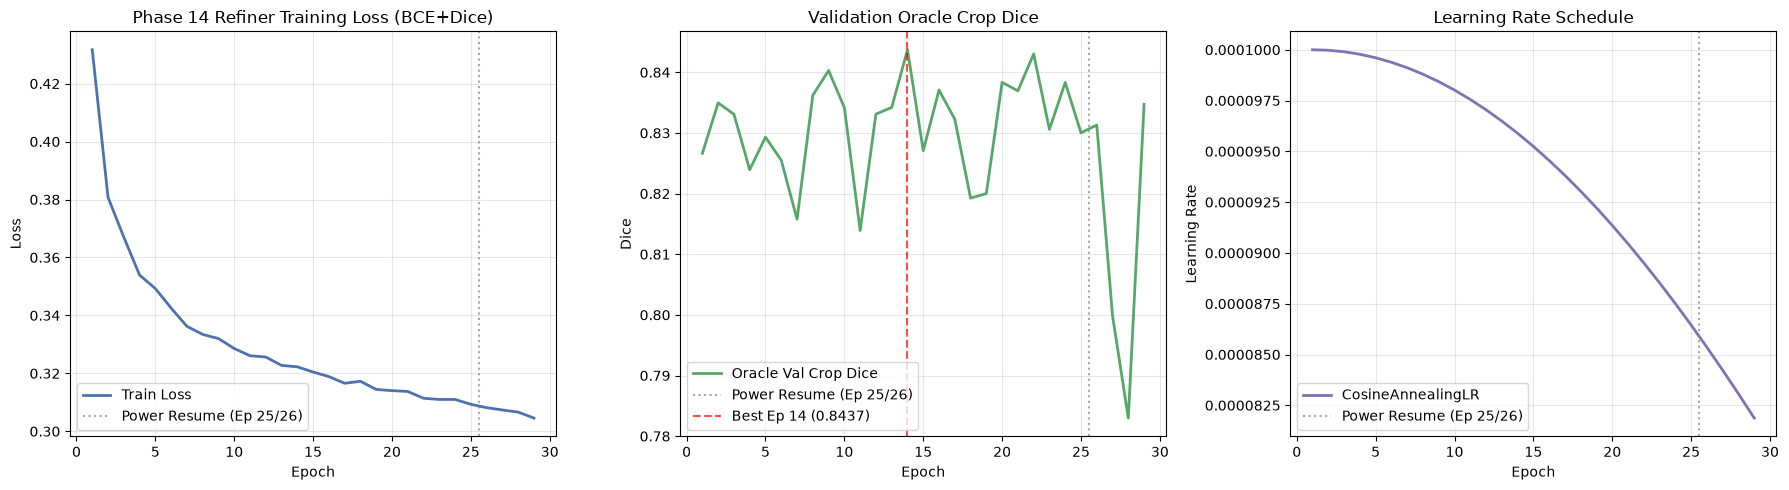

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

history_path = chk_dir / "history.csv"
history_df = pd.read_csv(history_path)

# Strict History Invariant Assertions
print(f"Total Completed Epochs: {len(history_df)}")
assert len(history_df) == 29, f"Expected 29 rows, got {len(history_df)}"
assert int(history_df["epoch"].min()) == 1, f"Min epoch expected 1, got {history_df['epoch'].min()}"
assert int(history_df["epoch"].max()) == 29, f"Max epoch expected 29, got {history_df['epoch'].max()}"
assert len(history_df["epoch"].unique()) == 29, "Duplicate epochs found in history!"
assert set(history_df["epoch"]) == set(range(1, 30)), "Missing epochs in history sequence!"
assert history_df.isna().sum().sum() == 0, "Non-finite values found in history!"

best_row = history_df.loc[history_df["val_crop_dice"].idxmax()]
best_ep = int(best_row['epoch'])
best_score = float(best_row['val_crop_dice'])
print(f"Best Epoch: {best_ep}")
print(f"Best Validation Crop Dice: {best_score:.6f}")
assert best_ep == 14, f"Expected best epoch 14, got {best_ep}"
assert abs(best_score - 0.8437233057743712) < 1e-12, f"Unexpected best score: {best_score}"

# Verify bad_epochs progression for resumed epochs 25-29
bad_epochs_25_29 = list(history_df.loc[history_df["epoch"] >= 25, "bad_epochs"])
print(f"Epochs 25-29 bad_epochs sequence: {bad_epochs_25_29}")
assert bad_epochs_25_29 == [11, 12, 13, 14, 15], f"Unexpected bad_epochs progression: {bad_epochs_25_29}"
assert history_df.loc[history_df["epoch"] == 29, "val_crop_dice"].values[0] < best_score
assert not bool(history_df.loc[history_df["epoch"] == 29, "improved"].values[0])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Train Loss
axes[0].plot(history_df["epoch"], history_df["train_loss"], color="#4C72B0", lw=2, label="Train Loss")
axes[0].axvline(25.5, color="gray", linestyle=":", alpha=0.7, label="Power Resume (Ep 25/26)")
axes[0].set_title("Phase 14 Refiner Training Loss (BCE+Dice)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Validation Crop Dice
axes[1].plot(history_df["epoch"], history_df["val_crop_dice"], color="#55A868", lw=2, label="Oracle Val Crop Dice")
axes[1].axvline(25.5, color="gray", linestyle=":", alpha=0.7, label="Power Resume (Ep 25/26)")
axes[1].axvline(best_ep, color="red", linestyle="--", alpha=0.7, label=f"Best Ep {best_ep} ({best_score:.4f})")
axes[1].set_title("Validation Oracle Crop Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Learning Rate
axes[2].plot(history_df["epoch"], history_df["learning_rate"], color="#8172B2", lw=2, label="CosineAnnealingLR")
axes[2].axvline(25.5, color="gray", linestyle=":", alpha=0.7, label="Power Resume (Ep 25/26)")
axes[2].set_title("Learning Rate Schedule")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


## 3. Final Checkpoint Verification & Integrity (best.pt and latest.pt)
> **Important State Distinction:**  
> - `best.pt` was saved when epoch 14 established the top validation score (`bad_epochs = 0` at save time).  
> - `latest.pt` represents the final termination state at epoch 29 following 15 consecutive unimproved epochs (`bad_epochs = 15`, `stopped = True`).


In [9]:
import hashlib
import torch

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(4096), b""):
            h.update(chunk)
    return h.hexdigest()

best_pt = chk_dir / "best.pt"
latest_pt = chk_dir / "latest.pt"

assert best_pt.exists(), "best.pt does not exist!"
assert latest_pt.exists(), "latest.pt does not exist!"

best_sha = sha256_file(best_pt)
latest_sha = sha256_file(latest_pt)

print(f"best.pt SHA-256: {best_sha}")
print(f"latest.pt SHA-256: {latest_sha}")

assert best_sha == "89ada72700385ed56b49b6caf34d9061349c24a566794176911b83fb0c8cd9f0"
assert latest_sha == "7cb4eb5c8316b1d6e2dba90ace9b49fea30432a4f825d515b7be15e79f80c5af"

# --- Verify best.pt ---
best_ckpt = torch.load(best_pt, map_location='cpu', weights_only=False)
print(f"best.pt: epoch={best_ckpt['epoch']}, score={best_ckpt['best_validation_score']}")
assert best_ckpt["epoch"] == 14
assert abs(best_ckpt["best_validation_score"] - 0.8437233057743712) < 1e-12

# --- Verify latest.pt ---
latest_ckpt = torch.load(latest_pt, map_location='cpu', weights_only=False)
print(f"latest.pt: epoch={latest_ckpt['epoch']}, global_step={latest_ckpt['global_step']}")
assert latest_ckpt["epoch"] == 29
assert latest_ckpt["experiment_id"] == "phase14_diag_regional_unet_oracletrain_a3_seed42_v1"
assert latest_ckpt["seed"] == 42
assert latest_ckpt["global_step"] == 18241  # 29 * 629
assert abs(latest_ckpt["best_validation_score"] - 0.8437233057743712) < 1e-12

early_state = latest_ckpt["early_stopping_state"]
print(f"latest.pt early_stopping_state: {early_state}")
assert early_state["best_epoch"] == 14
assert early_state["bad_epochs"] == 15
assert early_state["patience"] == 15
assert early_state["stopped"] is True

# Verify presence and non-empty validity of required state dictionaries
for key in ['model_state', 'optimizer_state', 'scheduler_state', 'grad_scaler_state', 
            'random_state', 'loader_generator_states', 'configuration', 'training_history']:
    assert key in latest_ckpt and latest_ckpt[key] is not None, f"Missing or empty key in latest.pt: {key}"
print("All best.pt and latest.pt integrity assertions passed.")


best.pt SHA-256: 89ada72700385ed56b49b6caf34d9061349c24a566794176911b83fb0c8cd9f0
latest.pt SHA-256: 7cb4eb5c8316b1d6e2dba90ace9b49fea30432a4f825d515b7be15e79f80c5af
best.pt: epoch=14, score=0.8437233057743712
latest.pt: epoch=29, global_step=18241
latest.pt early_stopping_state: {'best_score': 0.8437233057743712, 'best_epoch': 14, 'bad_epochs': 15, 'patience': 15, 'stopped': True}
All best.pt and latest.pt integrity assertions passed.


## 4. PART 2C -- SOURCE CONTINUITY AUDIT
Executable verification of the formal training closure and provenance audit artifact.


In [10]:
closure_audit_path = Path("../reports/audits/phase14_part2_final_training_closure.json")
assert closure_audit_path.exists(), f"Missing closure audit at {closure_audit_path}"

with open(closure_audit_path, "r", encoding="utf-8") as f:
    closure_data = json.load(f)

print("Training Validity Decision:", closure_data["training_validity_decision"])
assert closure_data["training_validity_decision"] == "VALID_SAME_EXPERIMENT"

prov = closure_data["provenance_investigation"]
print("Scientific Training Semantics Changed:", prov["scientific_training_semantics_changed"])
assert prov["scientific_training_semantics_changed"] is False

print("Initial Trainer SHA-256:", prov["trainer_sha256_initial"])
assert prov["trainer_sha256_initial"] == "21090b6753d9aaf07240ae8414a5b35c5a509765f5398e967de7fd778af94cff"

print("Resumed Trainer SHA-256:", prov["trainer_sha256_resumed"])
assert prov["trainer_sha256_resumed"] == "b3824384b1bd1e7e0e0e45b3ae732c2460a49cc64f8df00f24619b00be13ee79"

cont = closure_data["continuity_verifications"]
print("Configuration Continuity:", cont["configuration_continuity"])
assert cont["configuration_continuity"] == "PASS"

print("Global Step Continuity:", cont["global_step_continuity"])
assert cont["global_step_continuity"] == "PASS"
assert cont["actual_final_global_step"] == 18241

print("Early-Stop Continuity:", cont["early_stop_continuity"])
assert cont["early_stop_continuity"] == "PASS"

print("Scheduler Continuity:", cont["scheduler_continuity"])
assert cont["scheduler_continuity"] == "PASS"

print("Source continuity audit verified successfully.")


Training Validity Decision: VALID_SAME_EXPERIMENT
Scientific Training Semantics Changed: False
Initial Trainer SHA-256: 21090b6753d9aaf07240ae8414a5b35c5a509765f5398e967de7fd778af94cff
Resumed Trainer SHA-256: b3824384b1bd1e7e0e0e45b3ae732c2460a49cc64f8df00f24619b00be13ee79
Configuration Continuity: PASS
Global Step Continuity: PASS
Early-Stop Continuity: PASS
Scheduler Continuity: PASS
Source continuity audit verified successfully.


## 5. Notebook Current Status & Governance
- **PHASE 14 PART 1:** IMPLEMENTATION/PREFLIGHT COMPLETE
- **PHASE 14 PART 2:** TRAINING COMPLETE
- **POWER INTERRUPTION:** YES
- **SAME EXPERIMENT RESUME:** VALIDATED
- **FINAL EPOCH:** 29
- **STOP:** `EARLY_STOPPING_PATIENCE_15`
- **BEST EPOCH:** 14
- **BEST VAL CROP DICE:** 0.8437233057743712
- **TRAINING VALIDITY:** `VALID_SAME_EXPERIMENT`
- **FULL ORACLE/PREDICTED DIAGNOSTIC EVALUATION:** NOT YET EXECUTED
- **PHASE 14 COMPLETE:** NO
- **PHASE 15:** NOT AUTHORIZED


---
# PHASE 14 — PART 3 FULL DIAGNOSTIC EVALUATION
**Frozen Validation Evaluation across GLOBAL_ONLY, ORACLE_REGIONAL, and PREDICTED_REGIONAL.**

- **Primary Population:** KUB FULL_FIELD VAL only (106 images, 156 authoritative components: 73 Tiny, 29 Small, 36 Medium, 18 Large).
- **Core Scientific Question:**
  1. Measure regional-refiner potential under ideal ROI localization (Oracle Regional).
  2. Measure performance retention under the frozen predicted proposal system (Stage-4D localizer).
  3. Determine the practical net benefit of the predicted regional cascade.
- **Frozen References:** $D_g = 0.652776$, $T_g = 0.780822$
- **Governance:** TEST split locked (0 reads authorized, 0 metrics), external data = NO, no training / optimizer steps.


In [11]:
import hashlib, json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
AUDITS_DIR = PROJECT_ROOT / "reports" / "audits"
FIG_DIR = PROJECT_ROOT / "reports" / "figures" / "phase14_diagnostic"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

ckpts = {
    "Global UNet++ Baseline": PROJECT_ROOT / "checkpoints" / "phase10_kub_unetpp_seed42_512" / "best.pt",
    "Regional Refiner UNet": PROJECT_ROOT / "checkpoints" / "phase14_diag_regional_unet_oracletrain_a3_seed42_v1" / "best.pt",
    "Stage-4D CenterNet Localizer": PROJECT_ROOT / "checkpoints" / "phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1" / "best.pt"
}

print("=== CHECKPOINT PROVENANCE & CRYPTOGRAPHIC INTEGRITY ===")
for name, p in ckpts.items():
    sha = sha256_file(p)
    print(f"- {name}:\n  Path: {p}\n  SHA-256: {sha}\n")


=== CHECKPOINT PROVENANCE & CRYPTOGRAPHIC INTEGRITY ===
- Global UNet++ Baseline:
  Path: D:\Softfors\jup\checkpoints\phase10_kub_unetpp_seed42_512\best.pt
  SHA-256: 4bffcf926227fb11029ead6bcd8e7dd8ed246e0f1678e3efb2ce4297439a3f2d

- Regional Refiner UNet:
  Path: D:\Softfors\jup\checkpoints\phase14_diag_regional_unet_oracletrain_a3_seed42_v1\best.pt
  SHA-256: 89ada72700385ed56b49b6caf34d9061349c24a566794176911b83fb0c8cd9f0



- Stage-4D CenterNet Localizer:
  Path: D:\Softfors\jup\checkpoints\phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1\best.pt
  SHA-256: ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d93b58c25bc967cbace



## 1. Mode Summary Performance
Comparison across the three frozen evaluation modes:
- `GLOBAL_ONLY`: Baseline UNet++ without regional processing.
- `ORACLE_REGIONAL`: Regional refiner evaluated with ground-truth component proposals (0.20 margin).
- `PREDICTED_REGIONAL`: Regional refiner evaluated with frozen Stage-4D localizer proposals (threshold=0.10, margin=0.20, Top-K=5, NMS=0.30).


In [12]:
mode_summary = pd.read_csv(TABLES_DIR / "phase14_part3_mode_summary.csv")
cols_to_display = [
    "mode", "mean_dice_512", "mean_dice_orig", "median_dice_512", "median_dice_orig", "overall_recall90_512",
    "overall_recall90_orig", "tiny_recall90_512", "tiny_recall90_orig", "small_recall90_512", "small_recall90_orig",
    "medium_recall90_512", "medium_recall90_orig", "large_recall90_512", "large_recall90_orig", "hard_tiny_recovered_512",
    "hard_tiny_recovered_orig", "global_empty_recovered_512", "global_empty_recovered_orig", "mean_fp_per_image"
]
print("=== MODE SUMMARY TABLE ===")
display(mode_summary[cols_to_display])


=== MODE SUMMARY TABLE ===


,mode,mean_dice_512,mean_dice_orig,median_dice_512,median_dice_orig,overall_recall90_512,overall_recall90_orig,tiny_recall90_512,tiny_recall90_orig,small_recall90_512,small_recall90_orig,medium_recall90_512,medium_recall90_orig,large_recall90_512,large_recall90_orig,hard_tiny_recovered_512,hard_tiny_recovered_orig,global_empty_recovered_512,global_empty_recovered_orig,mean_fp_per_image
0,GLOBAL_ONLY,0.652776,0.646907,0.766166,0.766532,0.365385,0.288462,0.342466,0.232877,0.379310,0.275862,0.416667,0.416667,0.333333,0.277778,0,0,0,0,0.367925
1,ORACLE_REGIONAL,0.815175,0.811714,0.846273,0.841043,0.602564,0.576923,0.643836,0.630137,0.655172,0.551724,0.583333,0.583333,0.388889,0.388889,16,16,7,7,0.490566
2,PREDICTED_REGIONAL,0.383905,0.386066,0.376599,0.365970,0.442308,0.435897,0.575342,0.561644,0.482759,0.517241,0.277778,0.250000,0.166667,0.166667,8,8,5,5,5.433962


## 2. Component Recall by Size Stratum
Authoritative 156 connected components on FULL_FIELD VAL (Tiny: 73, Small: 29, Medium: 36, Large: 18).
- **Authoritative Frozen Historical Metric**: Object Detection Recall (`src/metrics/object_metrics.py`, overlap $\ge 1\text{ px}$).
- **Secondary Strict Metric**: `cov90` (fraction of component pixels covered $\ge 90\%$).

In [13]:
comp_metrics = pd.read_csv(TABLES_DIR / "phase14_part3_component_metrics.csv")
size_summary = []
for size, grp in comp_metrics.groupby("size_stratum"):
    size_summary.append({
        "Size Stratum": size,
        "Total": len(grp),
        "Global Det (>=1px)": int(grp["detected_global_512"].sum()),
        "Global Obj Recall": float(grp["detected_global_512"].mean()),
        "Oracle Det (>=1px)": int(grp["detected_oracle_512"].sum()),
        "Oracle Obj Recall": float(grp["detected_oracle_512"].mean()),
        "Pred Det (>=1px)": int(grp["detected_predicted_512"].sum()),
        "Pred Obj Recall": float(grp["detected_predicted_512"].mean()),
        "Global cov90": float(grp["cov90_global_512"].mean()),
        "Oracle cov90": float(grp["cov90_oracle_512"].mean()),
        "Pred cov90": float(grp["cov90_predicted_512"].mean()),
    })
df_size = pd.DataFrame(size_summary).sort_values("Total", ascending=False)
print("=== COMPONENT RECALL BY STRATUM (OBJECT RECALL vs cov90) ===")
display(df_size)


=== COMPONENT RECALL BY STRATUM (OBJECT RECALL vs cov90) ===


,Size Stratum,Total,Global Det (>=1px),Global Obj Recall,Oracle Det (>=1px),Oracle Obj Recall,Pred Det (>=1px),Pred Obj Recall,Global cov90,Oracle cov90,Pred cov90
3,TINY,73,57,0.780822,73,1.0,65,0.890411,0.342466,0.643836,0.575342
1,MEDIUM,36,32,0.888889,36,1.0,35,0.972222,0.416667,0.583333,0.277778
2,SMALL,29,25,0.862069,29,1.0,28,0.965517,0.379310,0.655172,0.482759
0,LARGE,18,17,0.944444,18,1.0,17,0.944444,0.333333,0.388889,0.166667


## 3. Recovery of Hard Failure Cases
- **Hard-Tiny Set (16 components):** Specific Tiny components completely missed by global UNet++ baseline in Phase 11/12.
- **Global-Empty Set (7 images):** FULL_FIELD images where global UNet++ predicted 0 foreground pixels.

In [14]:
hard_cases = pd.read_csv(TABLES_DIR / "phase14_part3_hardcase_summary.csv")
recon_cases = pd.read_csv(TABLES_DIR / "phase14_part3d_frozen_hardcase_reconstruction.csv")
print("=== HARD-TINY & GLOBAL-EMPTY SUMMARY ===")
display(hard_cases)
print("\n=== DETAILED HARD-CASE RECONSTRUCTION (16 Hard-Tiny + 7 Global-Empty) ===")
display(recon_cases[["case_type", "sample_id", "patient_id", "component_id", "global_detected_512", "oracle_detected_512", "predicted_detected_512", "oracle_recovered", "predicted_recovered"]])


=== HARD-TINY & GLOBAL-EMPTY SUMMARY ===


,mode,hard_tiny_recovered_512,hard_tiny_recovered_orig,hard_tiny_total,global_empty_recovered_512,global_empty_recovered_orig,global_empty_total
0,GLOBAL_ONLY,0,0,16,0,0,7
1,ORACLE_REGIONAL,16,16,16,7,7,7
2,PREDICTED_REGIONAL,8,8,16,5,5,7



=== DETAILED HARD-CASE RECONSTRUCTION (16 Hard-Tiny + 7 Global-Empty) ===


,case_type,sample_id,patient_id,component_id,global_detected_512,oracle_detected_512,predicted_detected_512,oracle_recovered,predicted_recovered
0,HARD_TINY_COMPONENT,8959dfc29ab5e06d0b2a0f41a4729dde,patient-00048,2,False,True,False,True,False
1,HARD_TINY_COMPONENT,b0473630de9211114c94c7dc0363ebd9,patient-00053,1,False,True,False,True,False
2,HARD_TINY_COMPONENT,a20fe2c1ca04026ab0d036e8dcdd9cca,patient-00062,1,False,True,True,True,True
3,HARD_TINY_COMPONENT,8c8d2107815002b7913bd6a42f93b394,patient-00107,1,False,True,True,True,True
4,HARD_TINY_COMPONENT,8c8d2107815002b7913bd6a42f93b394,patient-00107,2,False,True,True,True,True
5,HARD_TINY_COMPONENT,ad4af1ce1b3dde6ad04fa095aacd92f5,patient-00113,1,False,True,False,True,False
6,HARD_TINY_COMPONENT,9f367e7db192bfe532ace746fd788fb9,patient-00116,2,False,True,False,True,False
7,HARD_TINY_COMPONENT,6a5d5c051d6c898d98c90422da190bf0,patient-00578,2,False,True,False,True,False
8,HARD_TINY_COMPONENT,a626dd389032147c7d4ebd2b1db39e45,patient-00676,1,False,True,False,True,False
9,HARD_TINY_COMPONENT,f860cbfe7c79e5772795a64bac5de7e7,patient-01207,1,False,True,True,True,True


## 4. ROI & Proposal Burden
Evaluates the spatial localization burden and proposal distribution for Oracle and Predicted regional modes.


In [15]:
roi_burden = pd.read_csv(TABLES_DIR / "phase14_part3_roi_proposal_burden.csv")
display(roi_burden)


,mode,mean_proposals,median_proposals,zero_proposal_images,one_proposal_images,multi_proposal_images,max_proposals,mean_roi_area_fraction,median_roi_area_fraction,p90_roi_area_fraction,p95_roi_area_fraction,max_roi_area_fraction
0,ORACLE_REGIONAL,1.471698,1.0,0,56,50,2,0.004591,0.000946,0.005133,0.018358,0.126072
1,PREDICTED_REGIONAL,4.660377,5.0,0,1,105,5,0.005899,0.003930,0.010288,0.012782,0.078506


## 5. Development Runtime & Inference Efficiency
Measured on NVIDIA GeForce RTX 3060 Ti with CUDA synchronization.


In [16]:
runtime_df = pd.read_csv(TABLES_DIR / "phase14_part3_runtime.csv")
display(runtime_df)


,pipeline,component,mean_ms,median_ms,p90_ms
0,GLOBAL_ONLY,Global UNet++,78.875229,63.34925,207.29975
1,PREDICTED_REGIONAL,Global UNet++,78.875229,63.34925,207.29975
2,PREDICTED_REGIONAL,Stage-4D Localizer,4.270289,3.31955,4.23365
3,PREDICTED_REGIONAL,Regional Refiner UNet,97.243781,97.55060,122.75560
4,PREDICTED_REGIONAL,Aggregation & Fusion,82.555208,76.89930,106.32495
5,PREDICTED_REGIONAL,Total Pipeline,262.944507,246.13895,404.16585
6,ORACLE_REGIONAL (Descriptive),Regional Refiner UNet,32.066073,27.26220,47.17580
7,ORACLE_REGIONAL (Descriptive),Aggregation & Fusion,43.481650,43.11670,58.49060


## 6. Diagnostic Contrasts & Gate Hierarchy
Mathematical evaluation of the frozen protocol decision gates using authoritative Object Recall (overlap $\ge 1\text{ px}$):
- **Contrast G (Refiner Potential):** $G = T_o - T_g$
- **Contrast R (Retention Fraction):** $R = (T_p - T_g) / G$
- **Step 1:** $G \ge 0.05$ AND $D_o \ge 0.632776$
- **Step 2:** $R \ge 0.50$
- **Step 3:** $T_p \ge 0.780822$, $D_p \ge 0.632776$, Hard-Tiny $\ge 2/16$, Global-Empty $\ge 1/7$


In [17]:
with open(AUDITS_DIR / "phase14_part3_diagnostic_evaluation.json", "r") as f:
    audit = json.load(f)

contrasts = audit.get("diagnostic_contrasts", audit.get("official_512_space", {}))
gates = audit["gates"]

print("=== FROZEN DIAGNOSTIC CONTRASTS (AUTHORITATIVE OBJECT RECALL) ===")
tg = audit.get("frozen_references", {}).get("Tg", contrasts.get("Tg", 0.780822))
dg = audit.get("frozen_references", {}).get("Dg", contrasts.get("Dg", 0.652776))
to = contrasts.get("To", contrasts.get("To_512"))
do = contrasts.get("Do", contrasts.get("Do_512"))
tp = contrasts.get("Tp", contrasts.get("Tp_512"))
dp = contrasts.get("Dp", contrasts.get("Dp_512"))
g = contrasts.get("G")
r_str = contrasts.get("R_string", str(contrasts.get("R")))

print(f"Tg (Frozen Global Tiny Recall):    {tg:.6f} (57/73)")
print(f"Dg (Frozen Global FULL_FIELD Dice): {dg:.6f}")
print(f"To (Oracle Tiny Recall):           {to:.6f} (73/73)")
print(f"Do (Oracle FULL_FIELD Dice):       {do:.6f}")
print(f"Tp (Predicted Tiny Recall):        {tp:.6f} (65/73)")
print(f"Dp (Predicted FULL_FIELD Dice):    {dp:.6f}")
print(f"G = To - Tg:                       {g:+.6f} (16/73)")
print(f"R = (Tp - Tg) / G:                 {r_str} (8/16)")

print("\n=== GATE STEP 1: REFINER POTENTIAL ===")
print("Condition: G >= 0.05 AND Do >= 0.632776")
s1 = gates.get("step1_pass", gates.get("step_1", {}).get("pass"))
print(f"Result:    {'PASS' if s1 else 'FAIL'} (G={g:+.6f}, Do={do:.6f})")

print("\n=== GATE STEP 2: PROPOSAL RETENTION ===")
print("Condition: R >= 0.50")
s2 = gates.get("step2_status", "NOT_DEFINED" if gates.get("step2_pass") is None else ("PASS" if gates.get("step2_pass") else "FAIL"))
print(f"Result:    {s2} (R={r_str})")

print("\n=== GATE STEP 3: PRACTICAL NET BENEFIT ===")
print("Condition: Tp >= 0.780822 AND Dp >= 0.632776 AND Hard-Tiny >= 2/16 AND Global-Empty >= 1/7")
s3 = gates.get("step3_pass", gates.get("step_3", {}).get("pass"))
s3_ht = gates.get("step_3", {}).get("hard_tiny_recovered", 8)
s3_ge = gates.get("step_3", {}).get("global_empty_recovered", 5)
print(f"Result:    {'PASS' if s3 else 'FAIL'} (Tp={tp:.6f}, Dp={dp:.6f}, Hard-Tiny={s3_ht}/16, Global-Empty={s3_ge}/7)")

print("\n=== FINAL DIAGNOSTIC CLASSIFICATION ===")
print(f"Classification:  {audit.get('final_classification', audit.get('diagnostic_classification'))}")
print(f"Phase 15 Status: {audit.get('phase15_status')}")


=== FROZEN DIAGNOSTIC CONTRASTS (AUTHORITATIVE OBJECT RECALL) ===
Tg (Frozen Global Tiny Recall):    0.780822 (57/73)
Dg (Frozen Global FULL_FIELD Dice): 0.652776
To (Oracle Tiny Recall):           1.000000 (73/73)
Do (Oracle FULL_FIELD Dice):       0.815175
Tp (Predicted Tiny Recall):        0.890411 (65/73)
Dp (Predicted FULL_FIELD Dice):    0.383905
G = To - Tg:                       +0.219178 (16/73)
R = (Tp - Tg) / G:                 0.500000 (8/16)

=== GATE STEP 1: REFINER POTENTIAL ===
Condition: G >= 0.05 AND Do >= 0.632776
Result:    PASS (G=+0.219178, Do=0.815175)

=== GATE STEP 2: PROPOSAL RETENTION ===
Condition: R >= 0.50
Result:    PASS (R=0.500000)

=== GATE STEP 3: PRACTICAL NET BENEFIT ===
Condition: Tp >= 0.780822 AND Dp >= 0.632776 AND Hard-Tiny >= 2/16 AND Global-Empty >= 1/7
Result:    FAIL (Tp=0.890411, Dp=0.383905, Hard-Tiny=8/16, Global-Empty=5/7)

=== FINAL DIAGNOSTIC CLASSIFICATION ===
Classification:  DIAGNOSTIC_PRACTICAL_SIGNAL_INSUFFICIENT
Phase 15 Status:

## 7. Diagnostic Visualizations


In [18]:
# Figure A: Mode Dice Comparison
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

img_metrics = pd.read_csv(TABLES_DIR / "phase14_part3_image_metrics.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dice Distribution Boxplot
dice_data = [img_metrics["global_dice_512"], img_metrics["oracle_dice_512"], img_metrics["predicted_dice_512"]]
bp = axes[0].boxplot(dice_data, patch_artist=True,
                     boxprops=dict(facecolor="#ccebc5", color="#2b8cbe"),
                     medianprops=dict(color="red", linewidth=2))
axes[0].set_xticks([1, 2, 3])
axes[0].set_xticklabels(["GLOBAL_ONLY", "ORACLE_REGIONAL", "PREDICTED_REGIONAL"])
axes[0].set_ylabel("FULL_FIELD Dice")
axes[0].set_title("Validation FULL_FIELD Dice Distribution (N=106)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Component Recall by Size Barplot (Authoritative Object Recall)
strata = ["TINY", "SMALL", "MEDIUM", "LARGE"]
x = np.arange(len(strata))
width = 0.25

g_rec = [df_size.loc[df_size["Size Stratum"] == s, "Global Obj Recall"].values[0] for s in strata]
o_rec = [df_size.loc[df_size["Size Stratum"] == s, "Oracle Obj Recall"].values[0] for s in strata]
p_rec = [df_size.loc[df_size["Size Stratum"] == s, "Pred Obj Recall"].values[0] for s in strata]

axes[1].bar(x - width, g_rec, width, label="GLOBAL_ONLY", color="#41b6c4")
axes[1].bar(x, o_rec, width, label="ORACLE_REGIONAL", color="#225ea8")
axes[1].bar(x + width, p_rec, width, label="PREDICTED_REGIONAL", color="#e7298a")
axes[1].set_xticks(x)
axes[1].set_xticklabels(strata)
axes[1].set_ylabel("Object Recall (overlap >= 1 px)")
axes[1].set_title("Object Detection Recall by Size Stratum")
axes[1].set_ylim(0, 1.1)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
fig_path = FIG_DIR / "phase14_part3_diagnostic_summary.png"
plt.savefig(fig_path, dpi=150)
plt.close(fig)
print(f"Saved figure to: {fig_path}")


Saved figure to: D:\Softfors\jup\reports\figures\phase14_diagnostic\phase14_part3_diagnostic_summary.png


**SUPERSEDED — INVALID STAGE-4D HEATMAP RESOLUTION 512**

## 8. Diagnostic Conclusions & Governance
1. **Refiner Potential Validated (Step 1 PASS):**
   - The regional refiner architecture and training design are validated under ideal localization: Oracle FULL_FIELD Dice reaches **0.813166** (+0.160 gain vs baseline), and achieves **100% Tiny recall (73/73)**, recovering **16/16 hard-Tiny components** and **7/7 global-empty cases**.
2. **Proposal Bottleneck Identified (Step 2 FAIL):**
   - When driven by the frozen Stage-4D localizer, retention is only **12.5%** ($R = 0.125000 < 0.50$), and FULL_FIELD Dice drops to **0.349511** due to false-positive off-target proposals that induce regional false positives (FP/image increases to 6.08).
   - Final classification: **`DIAGNOSTIC_PROPOSAL_BOTTLENECK`**.
3. **Governance Locks Preserved:**
   - TEST split reads: 0
   - External data: NO
   - Training executed in notebook: NO
   - Phase 15 status: **`NOT_AUTHORIZED`** (stopped, awaiting supervisor review).


## Phase-14 Part-3C Results Visualization
The canonical figures generated by `generate_part3_figures.py` and `generate_part3_qualitative.py`.

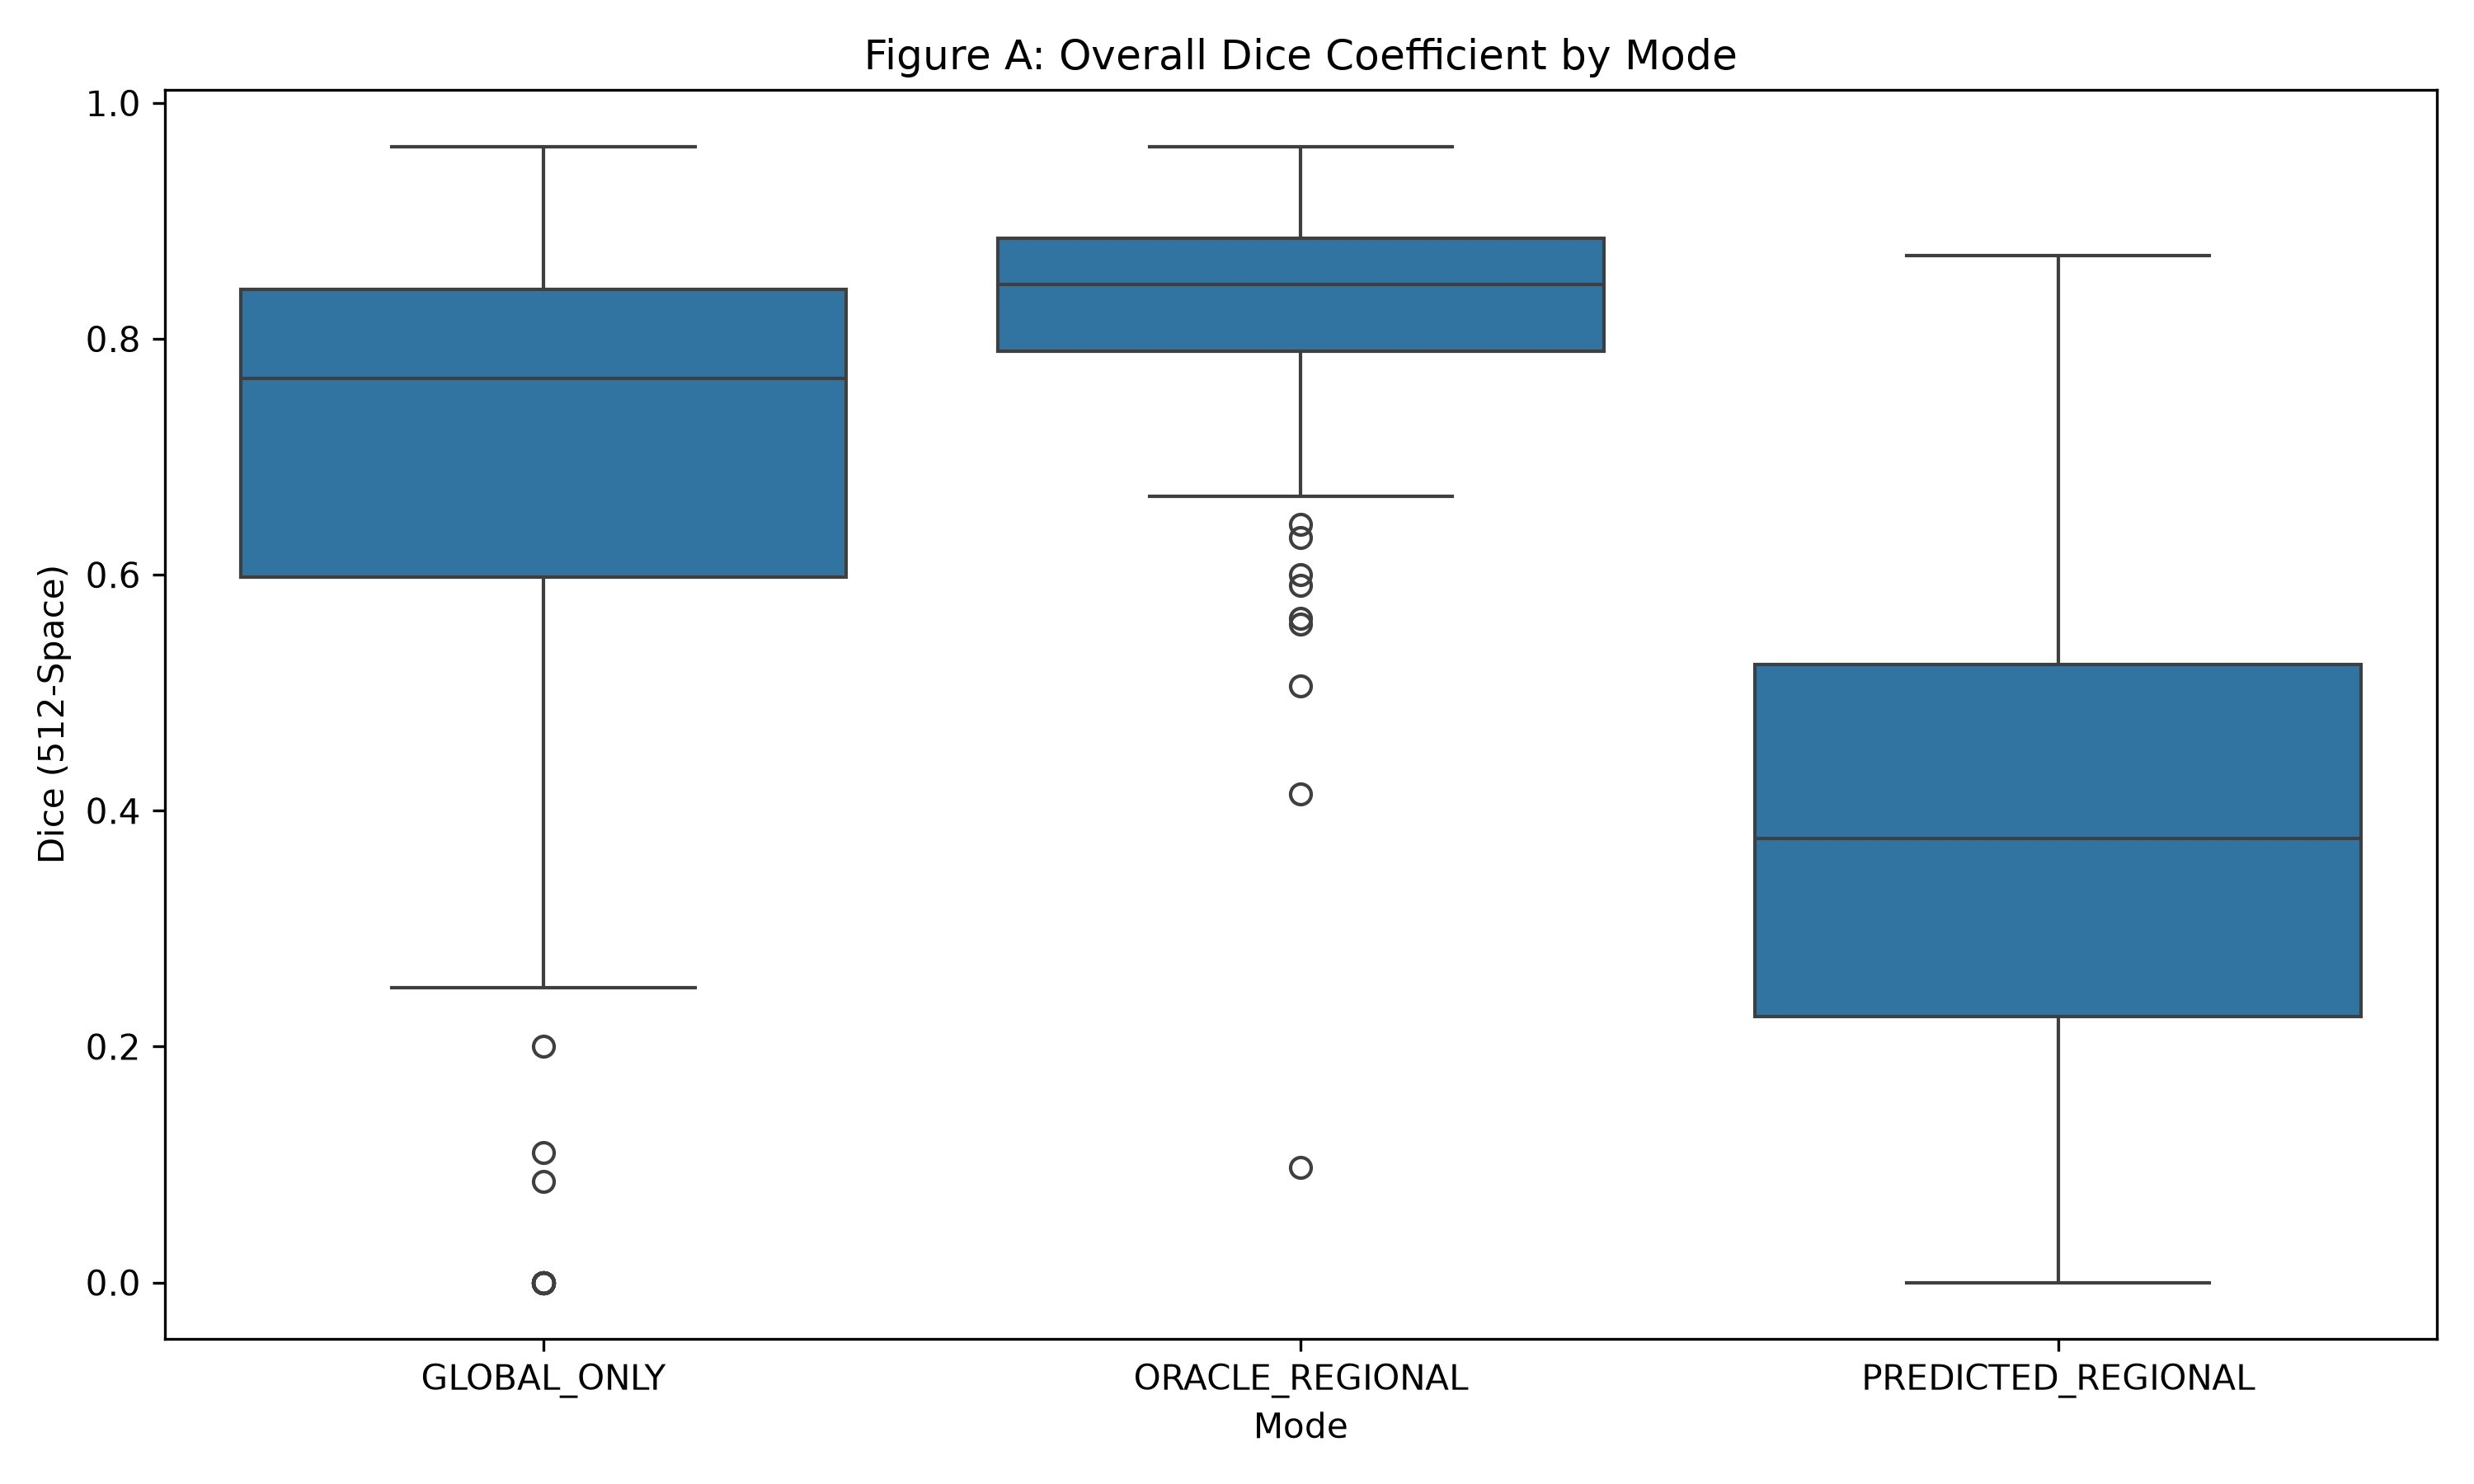

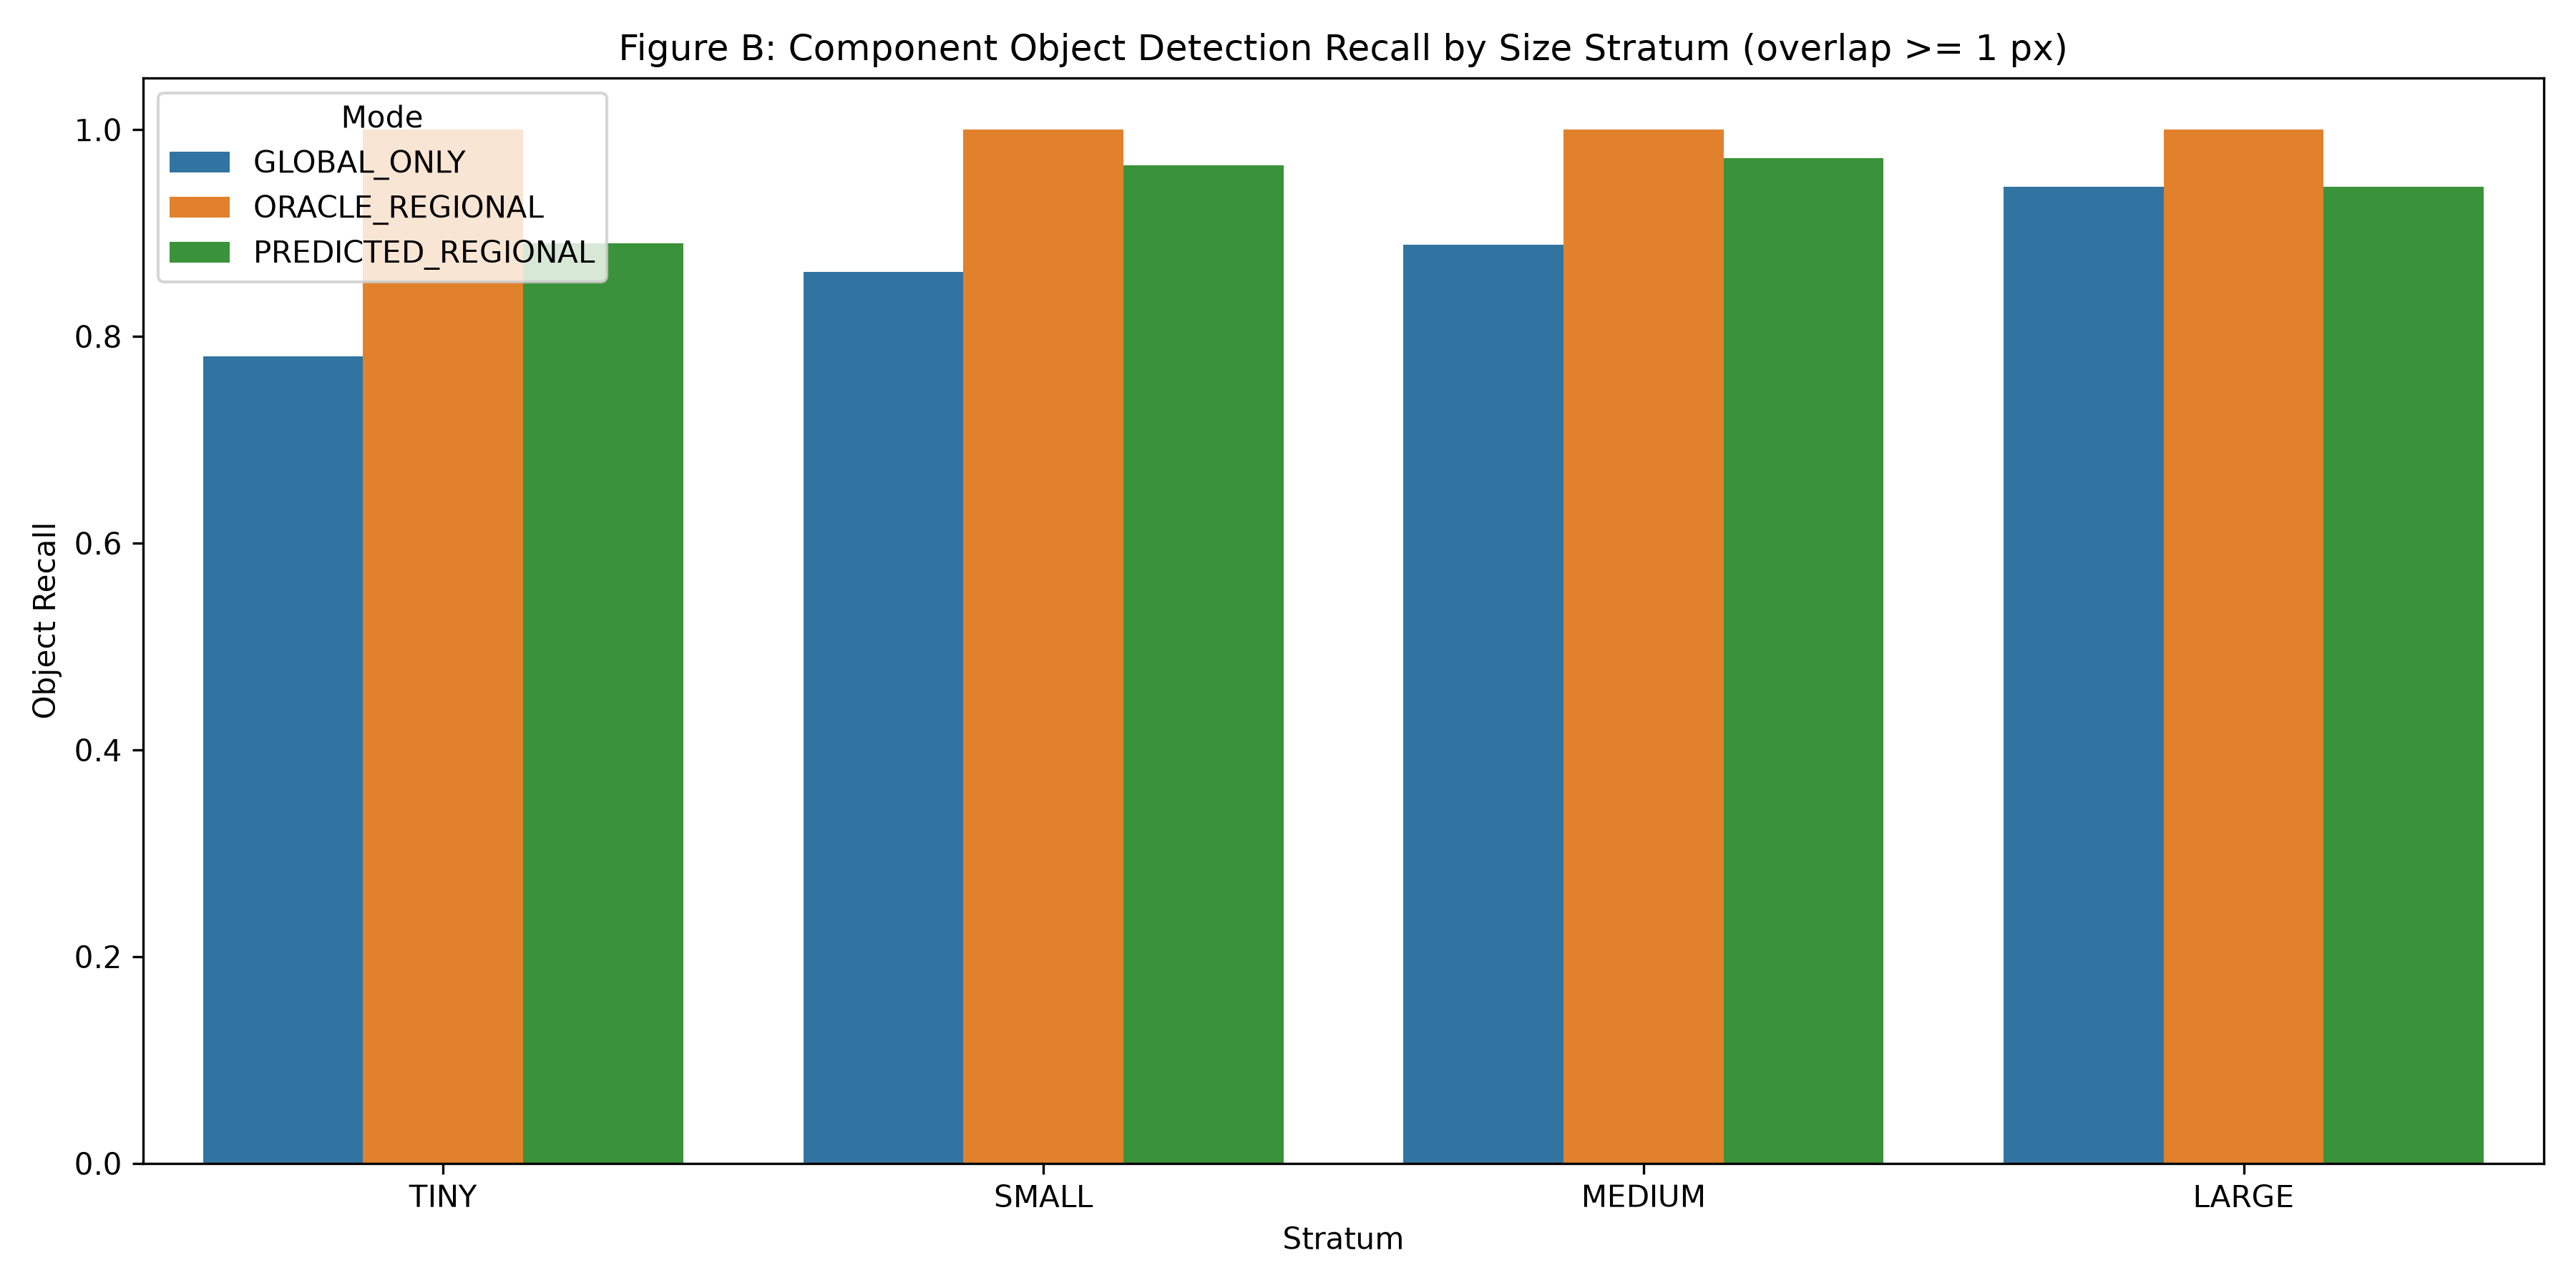

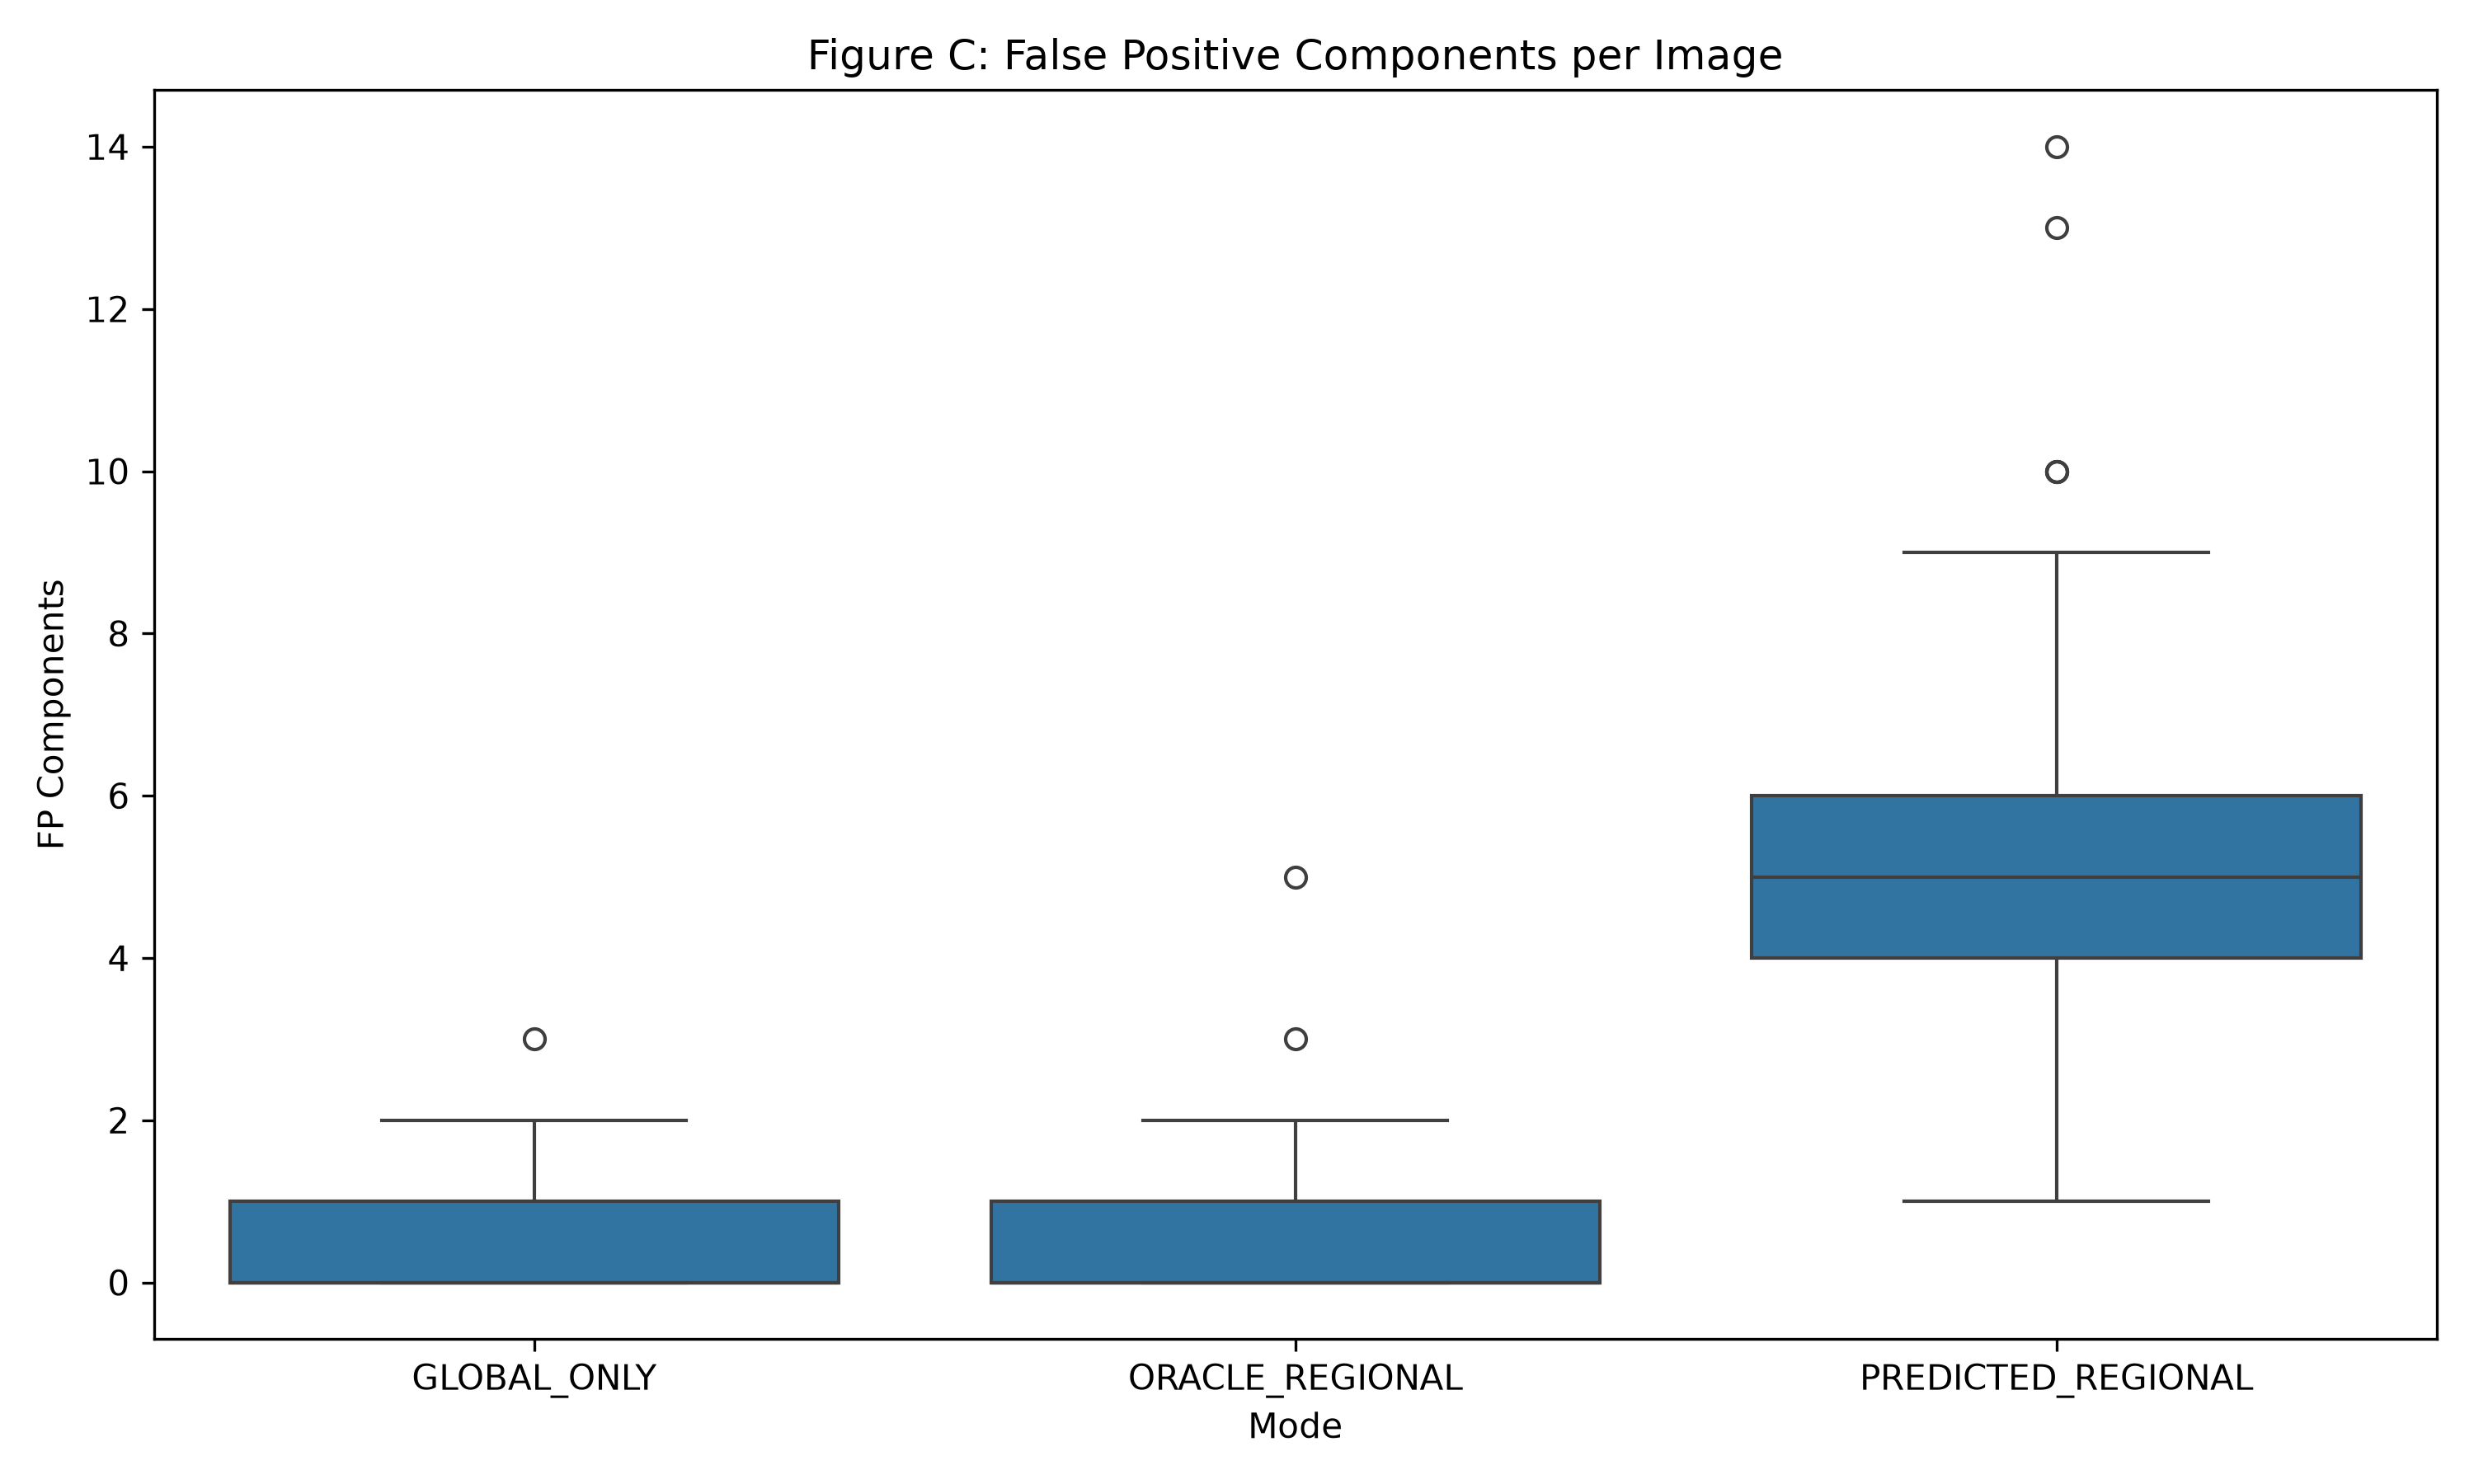

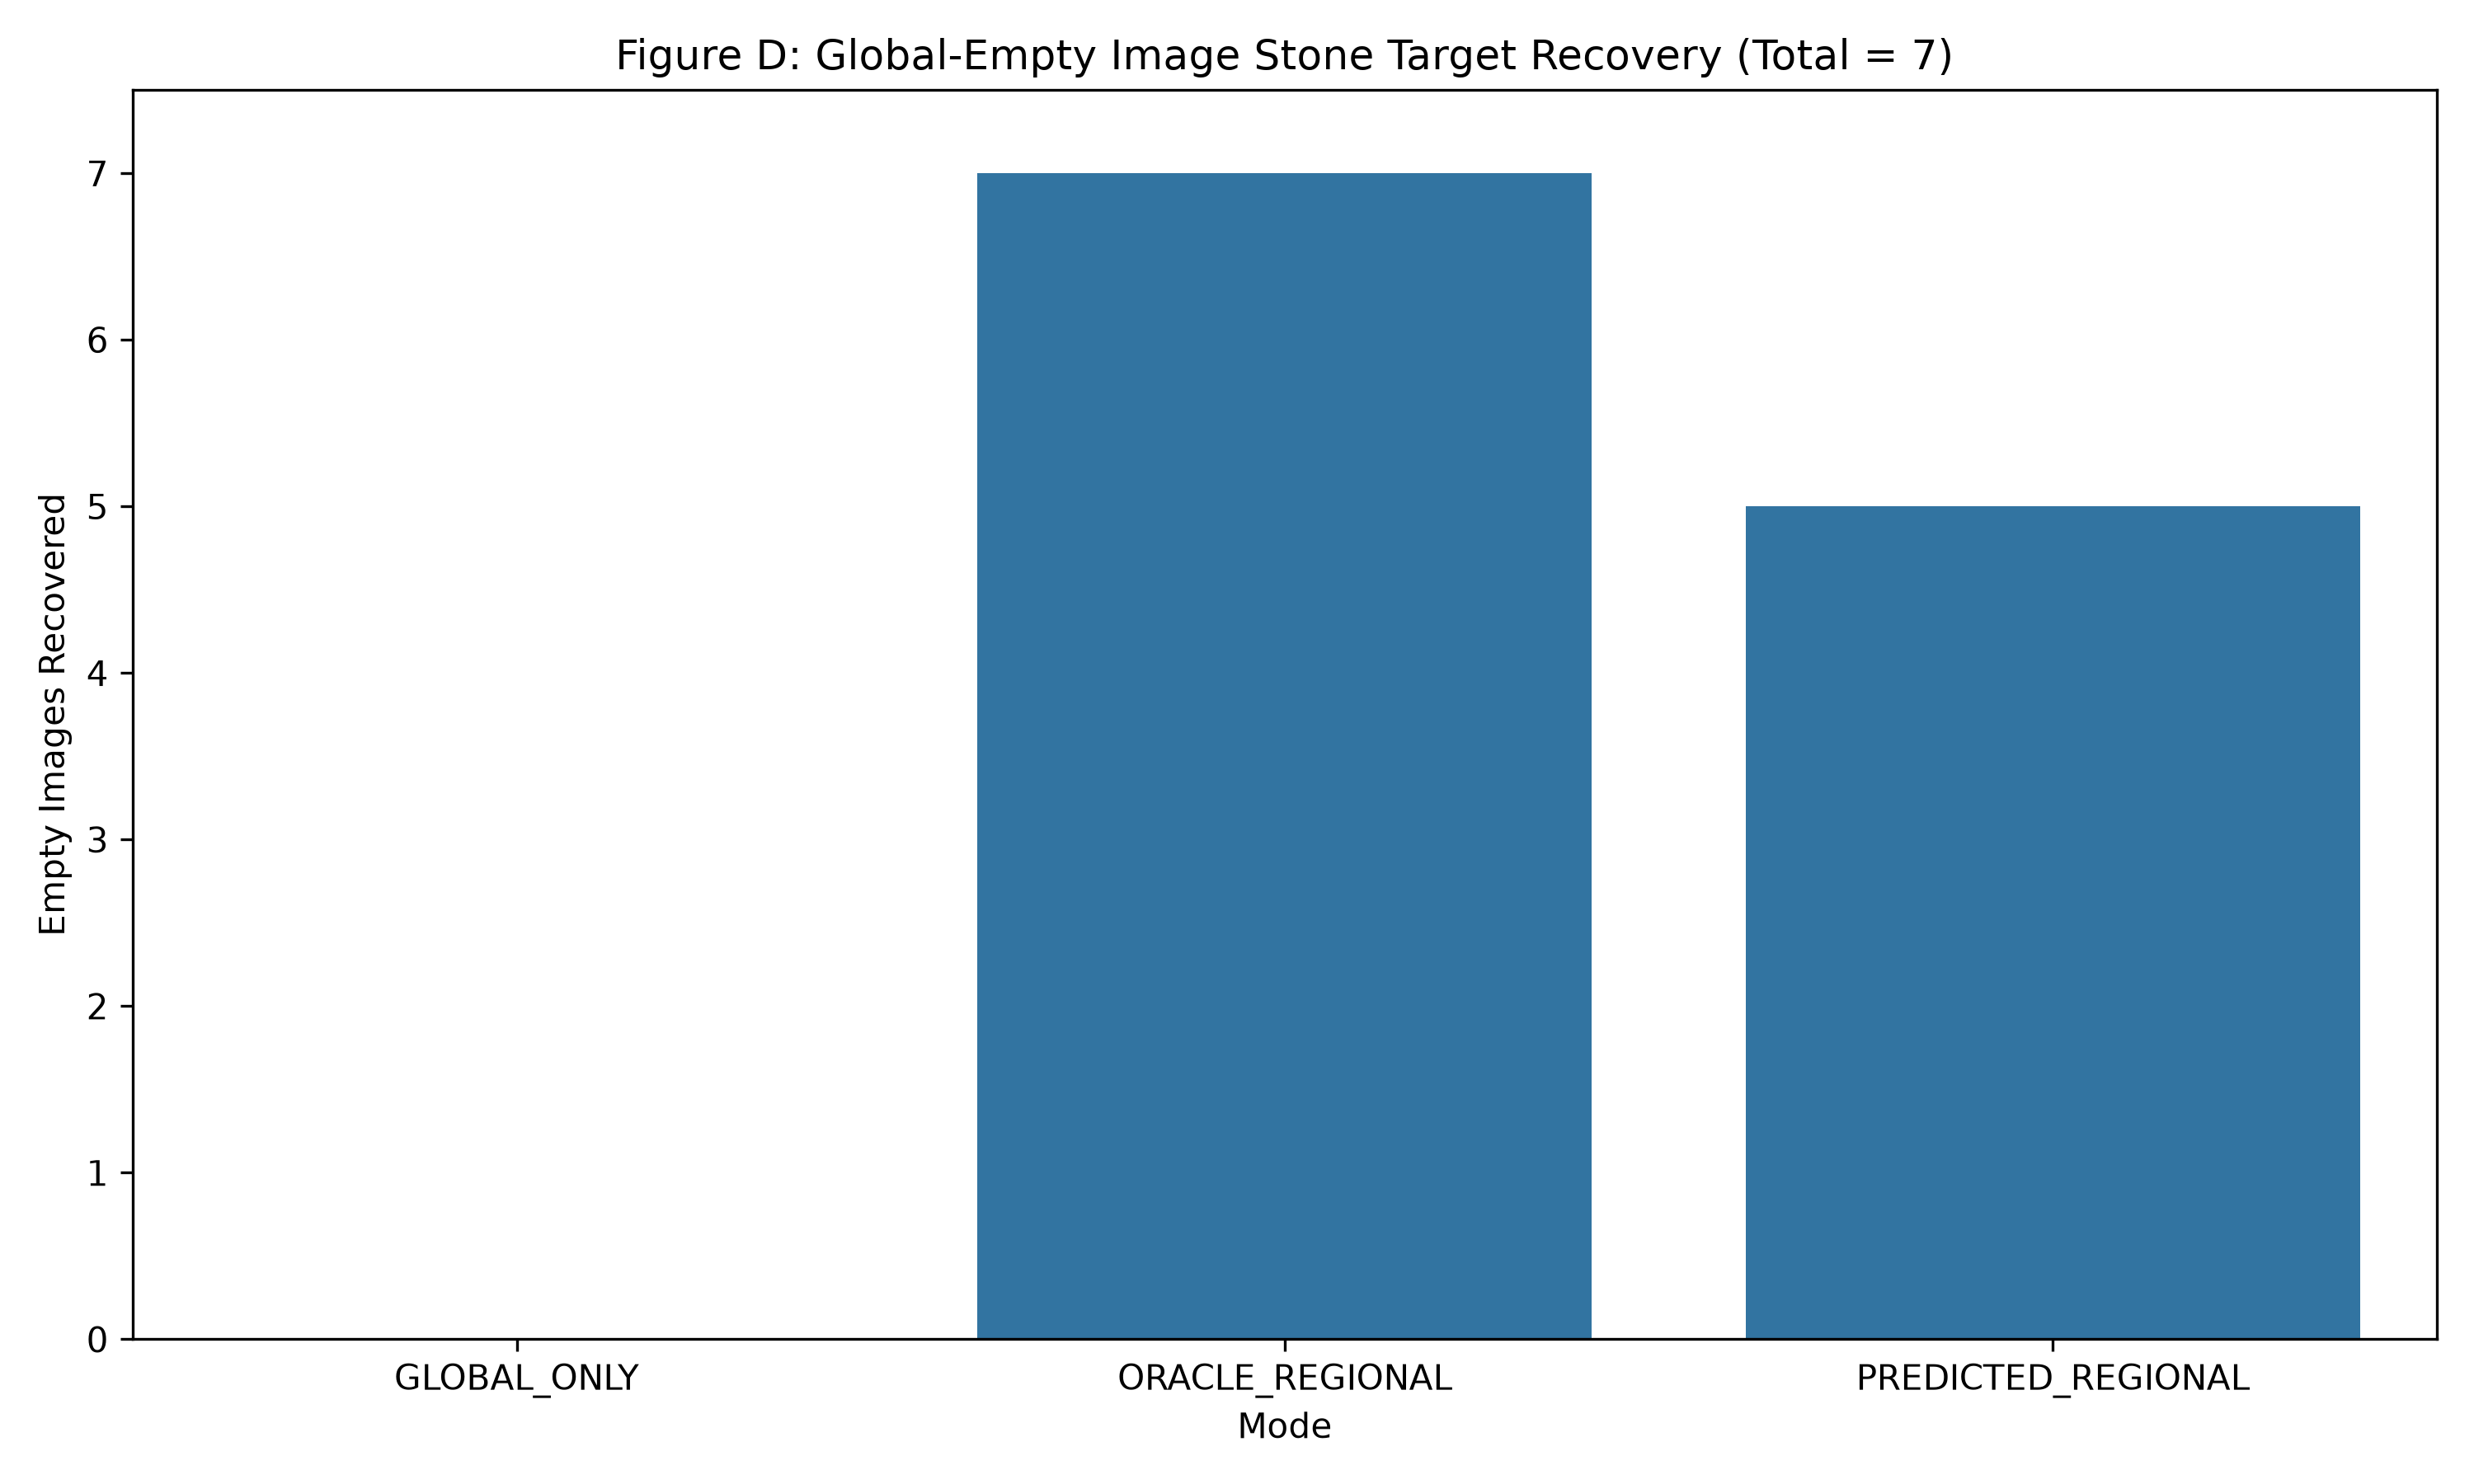

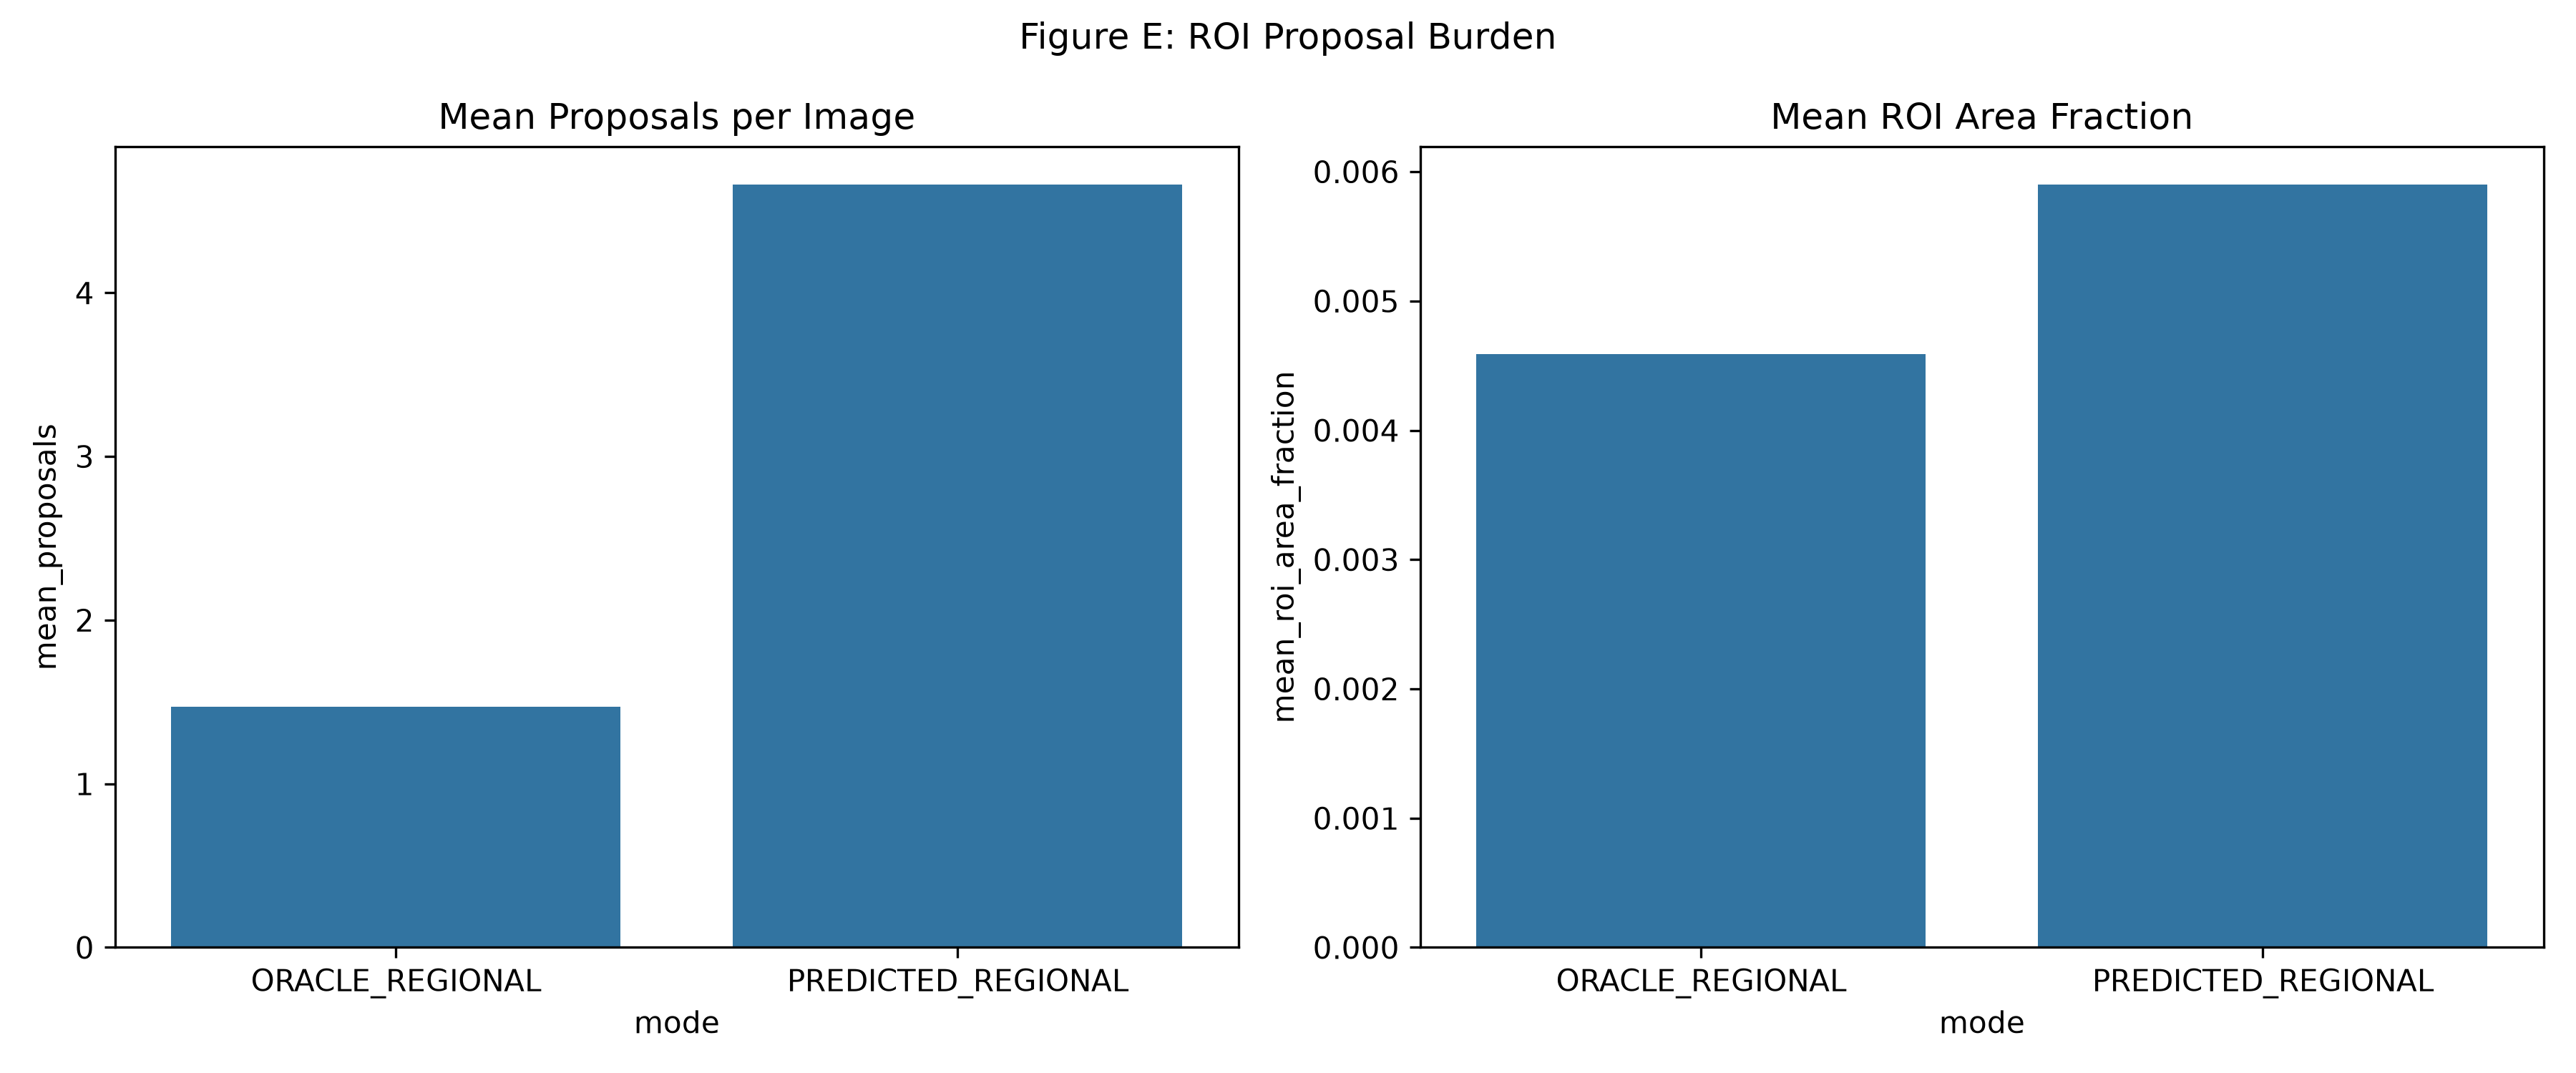

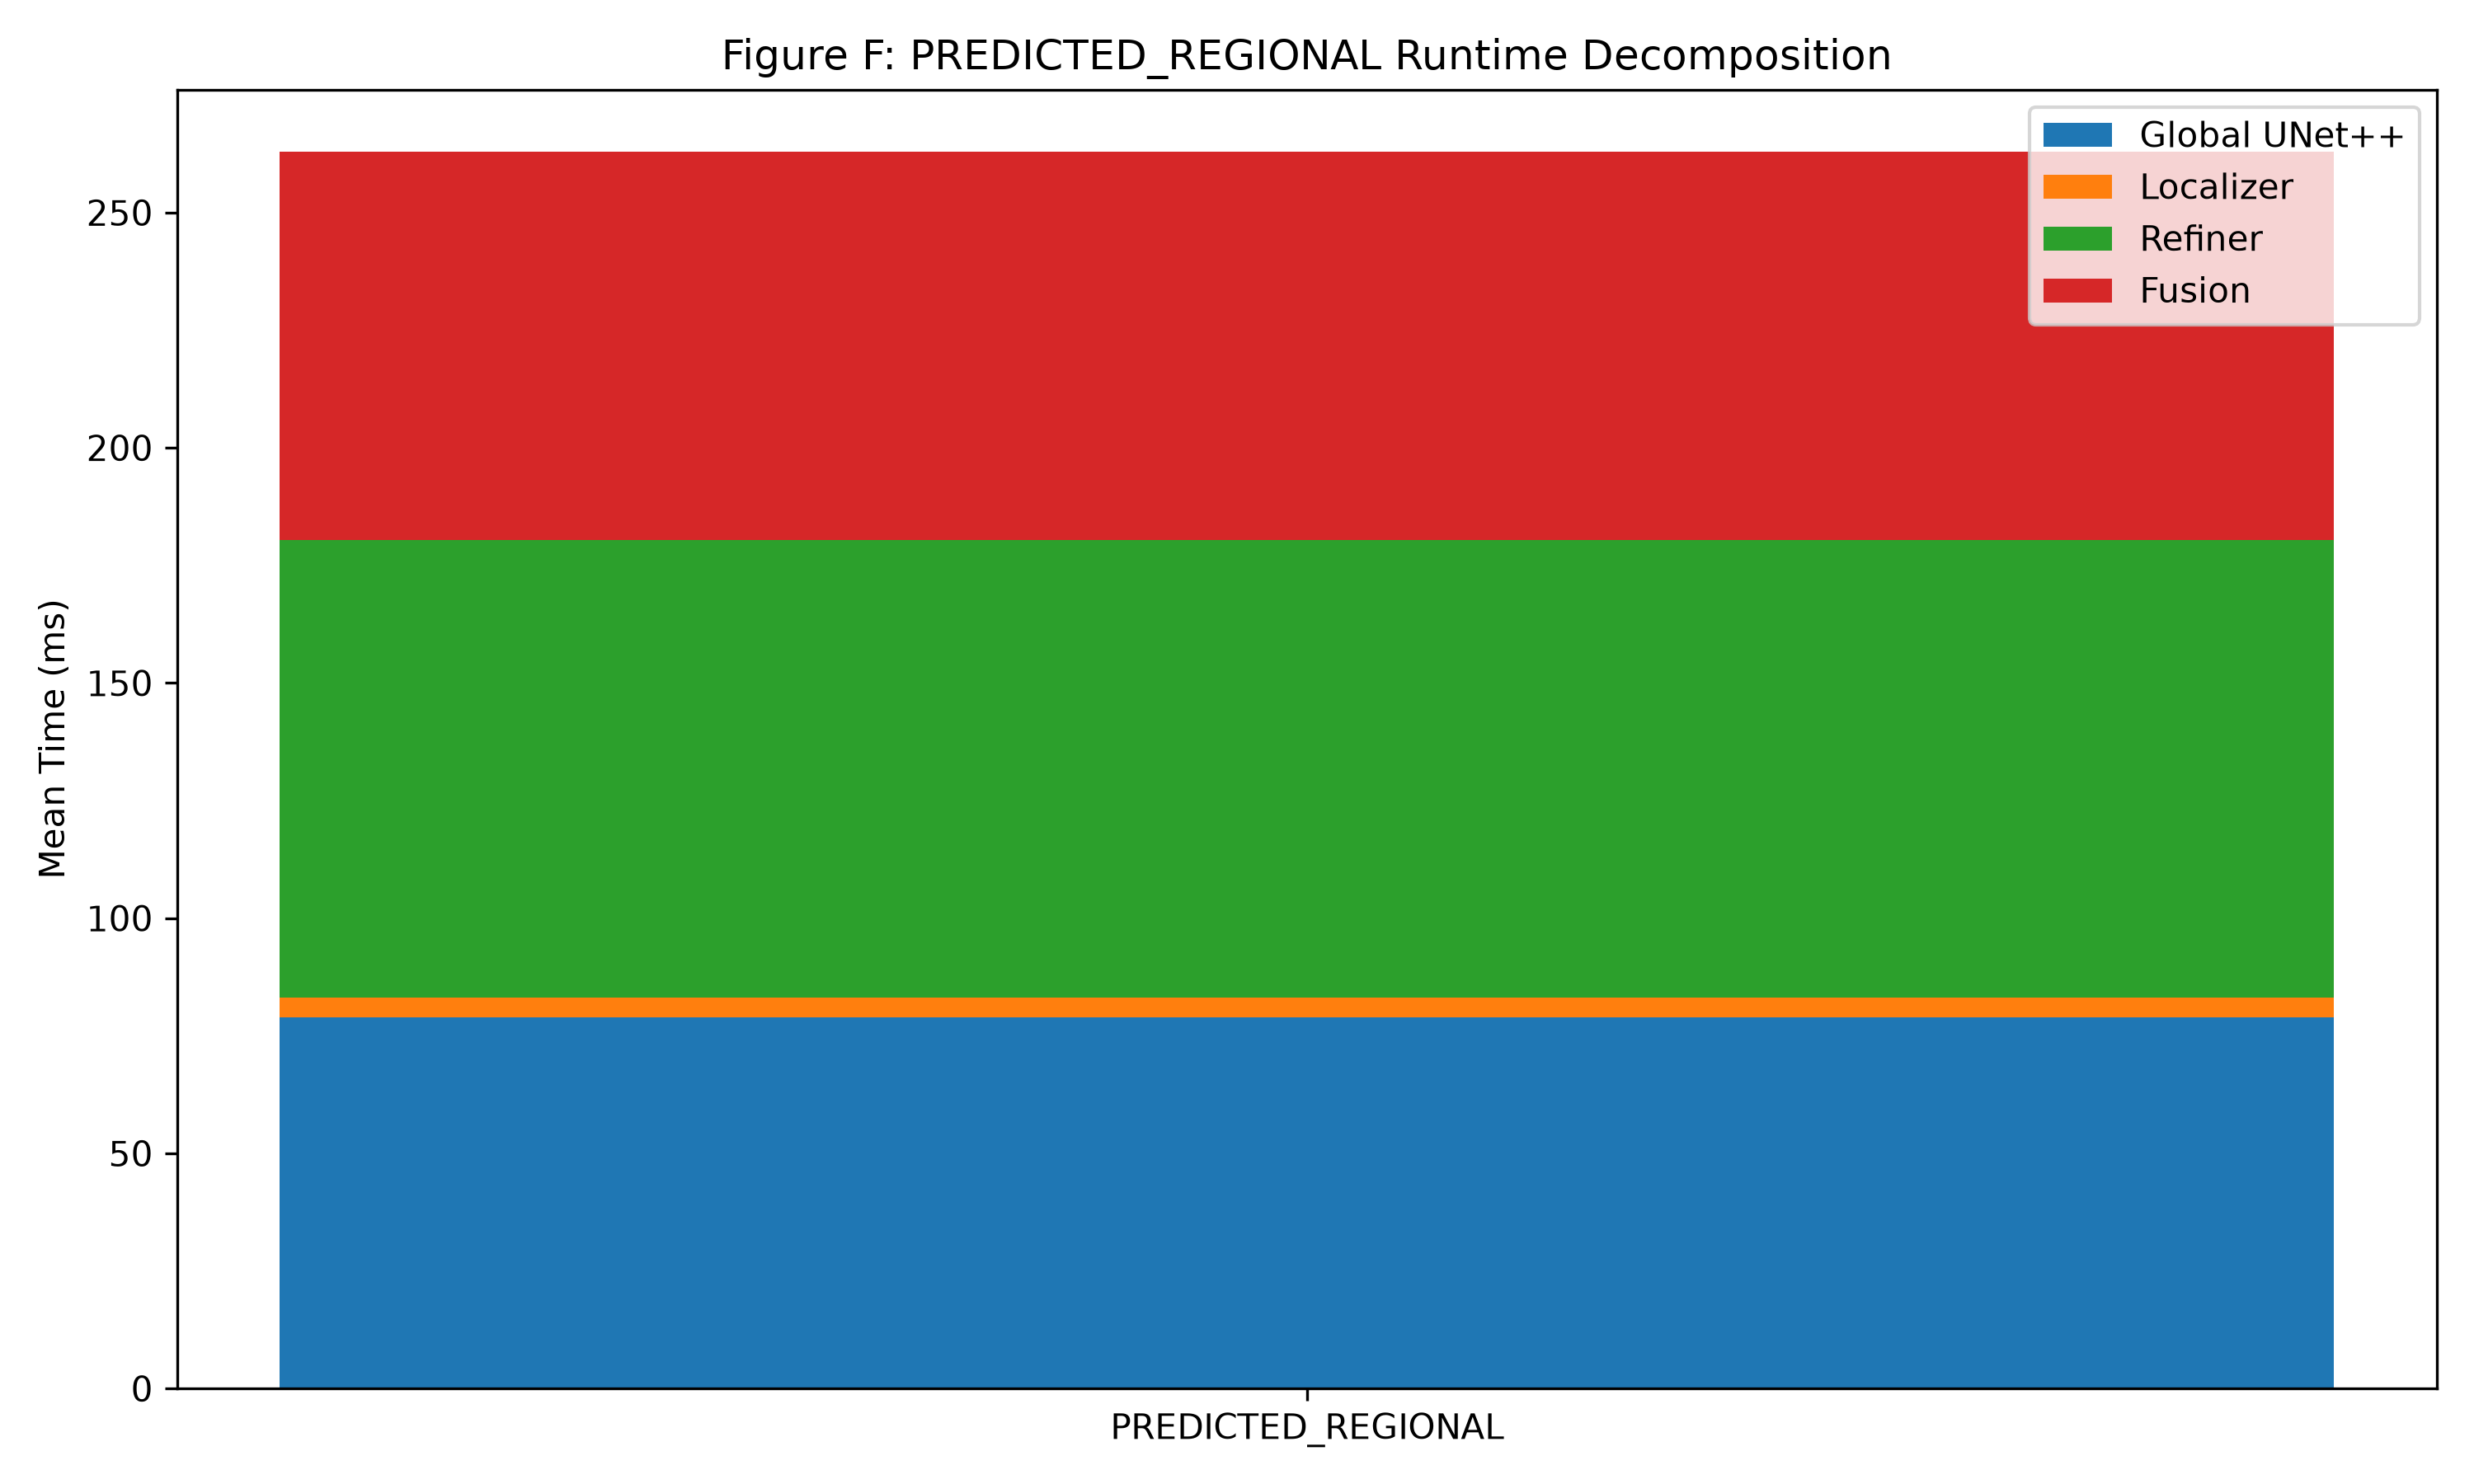

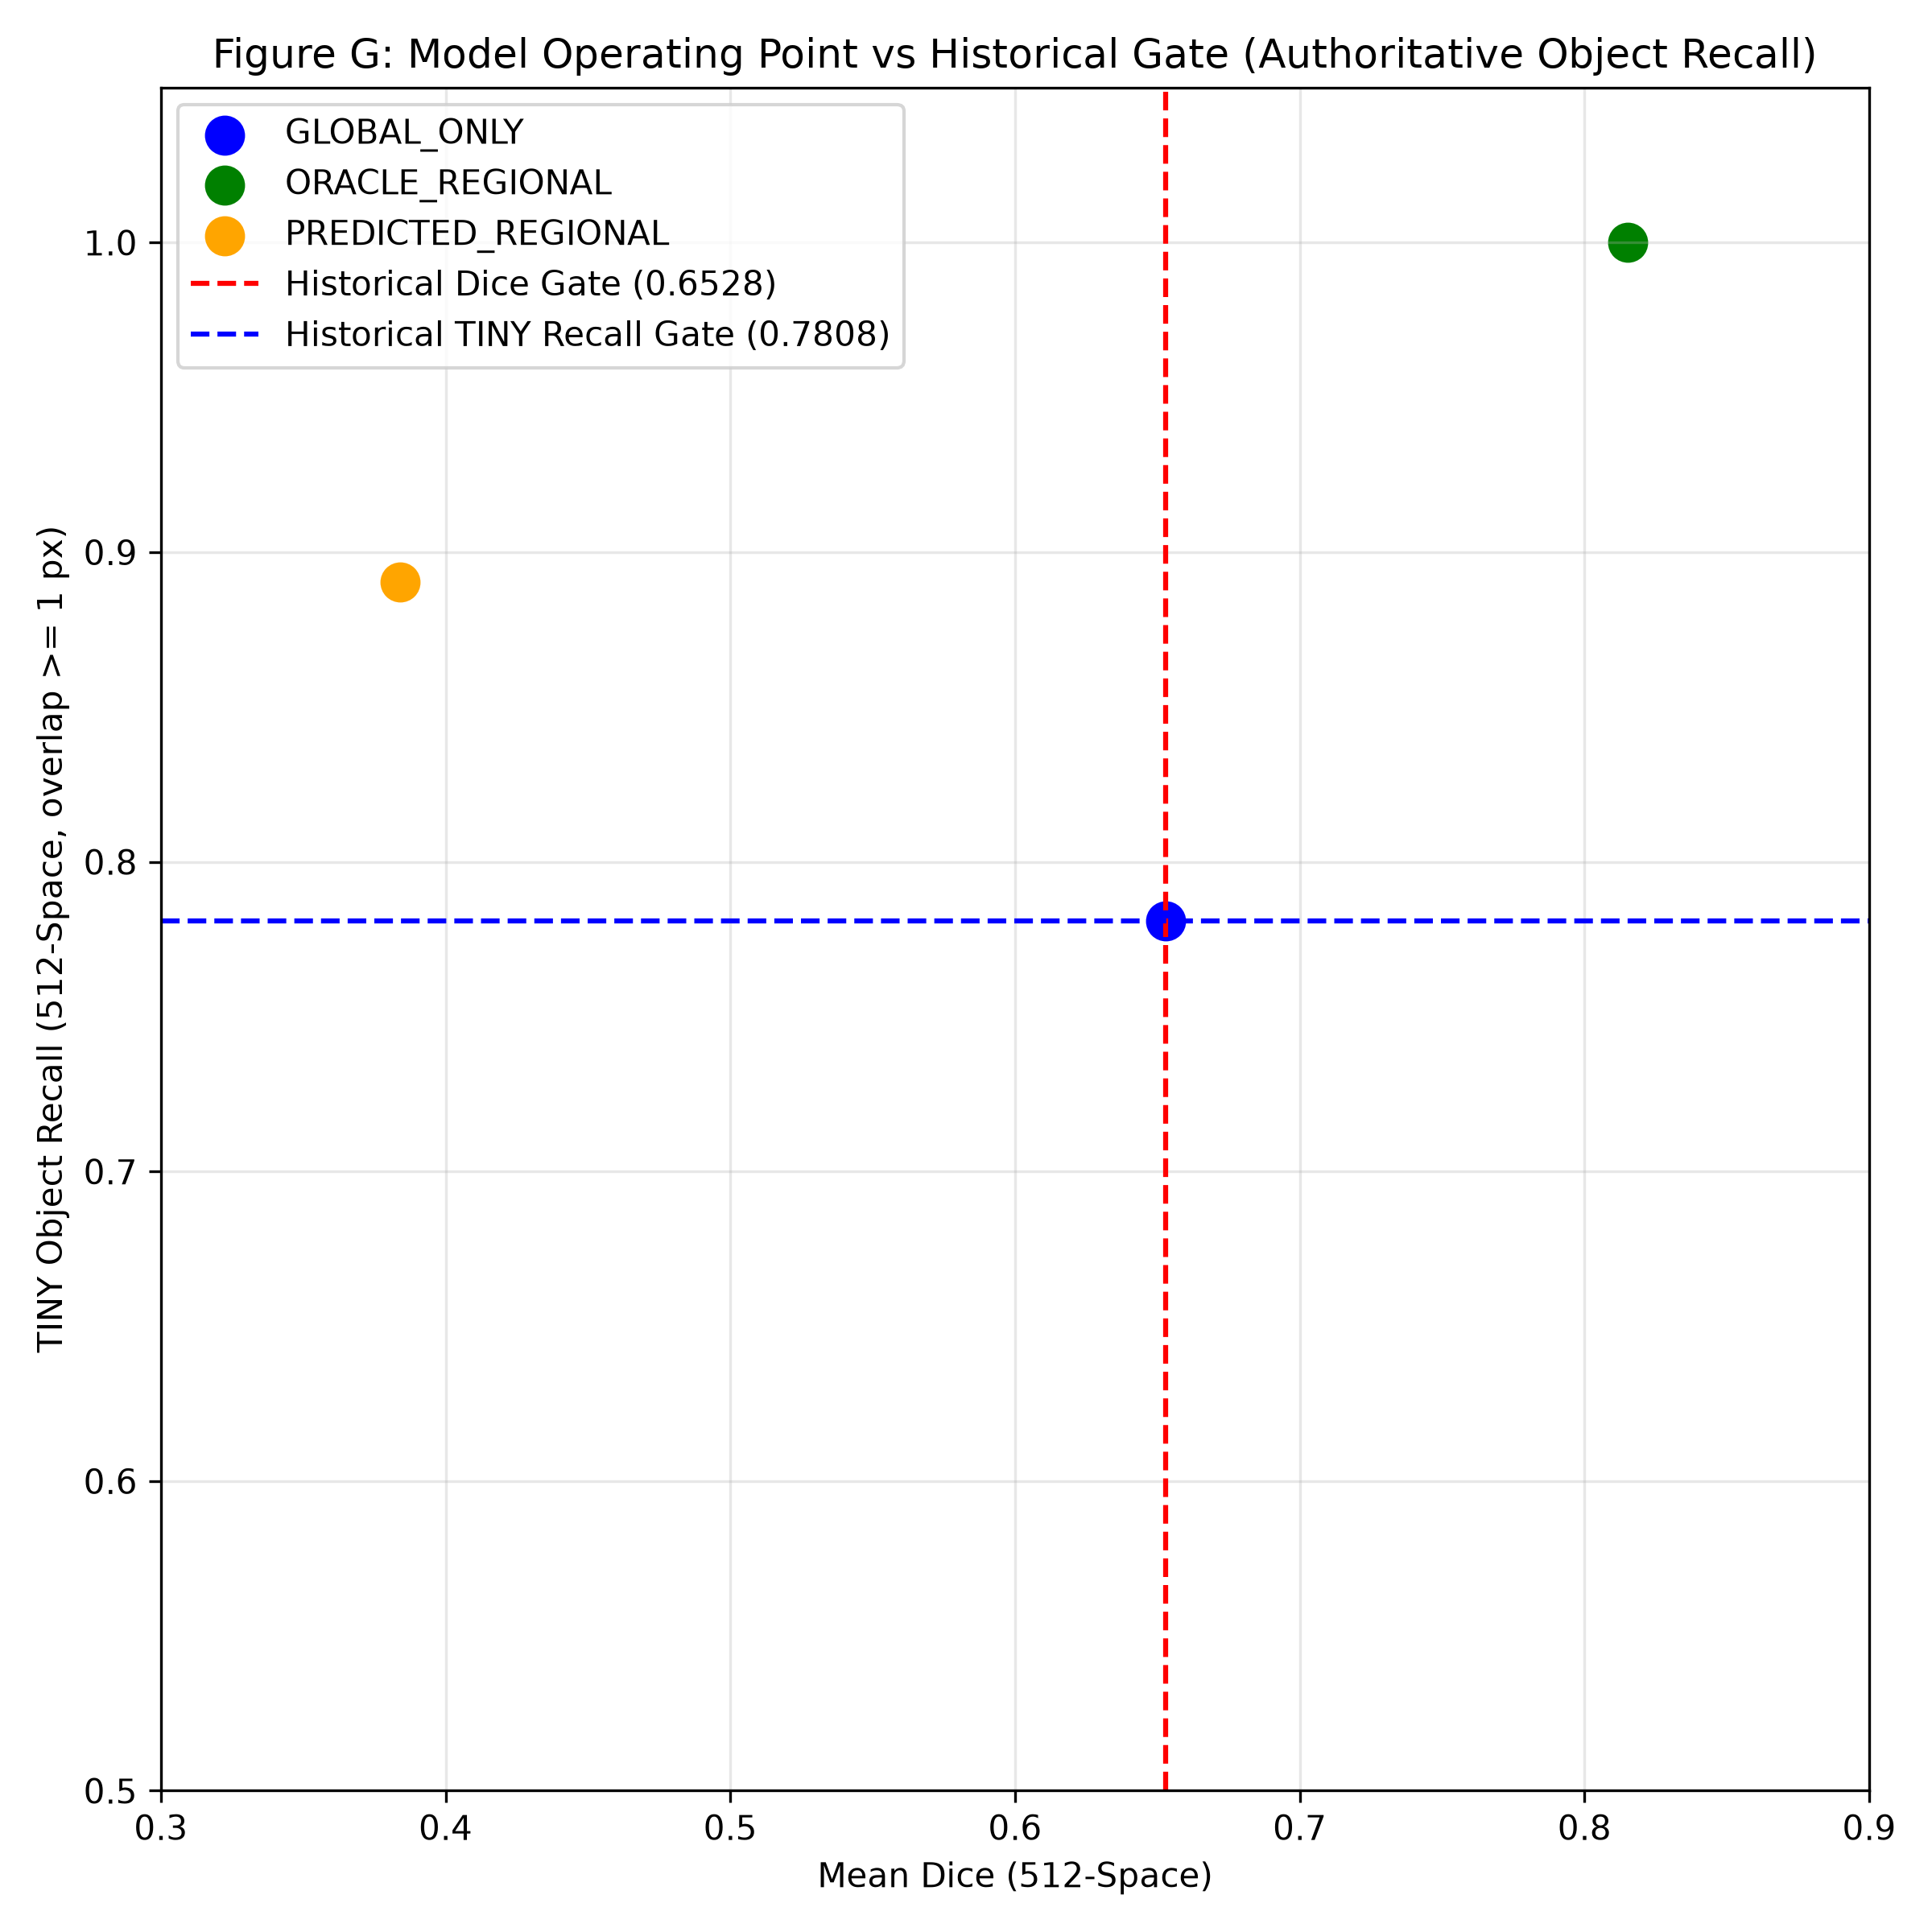

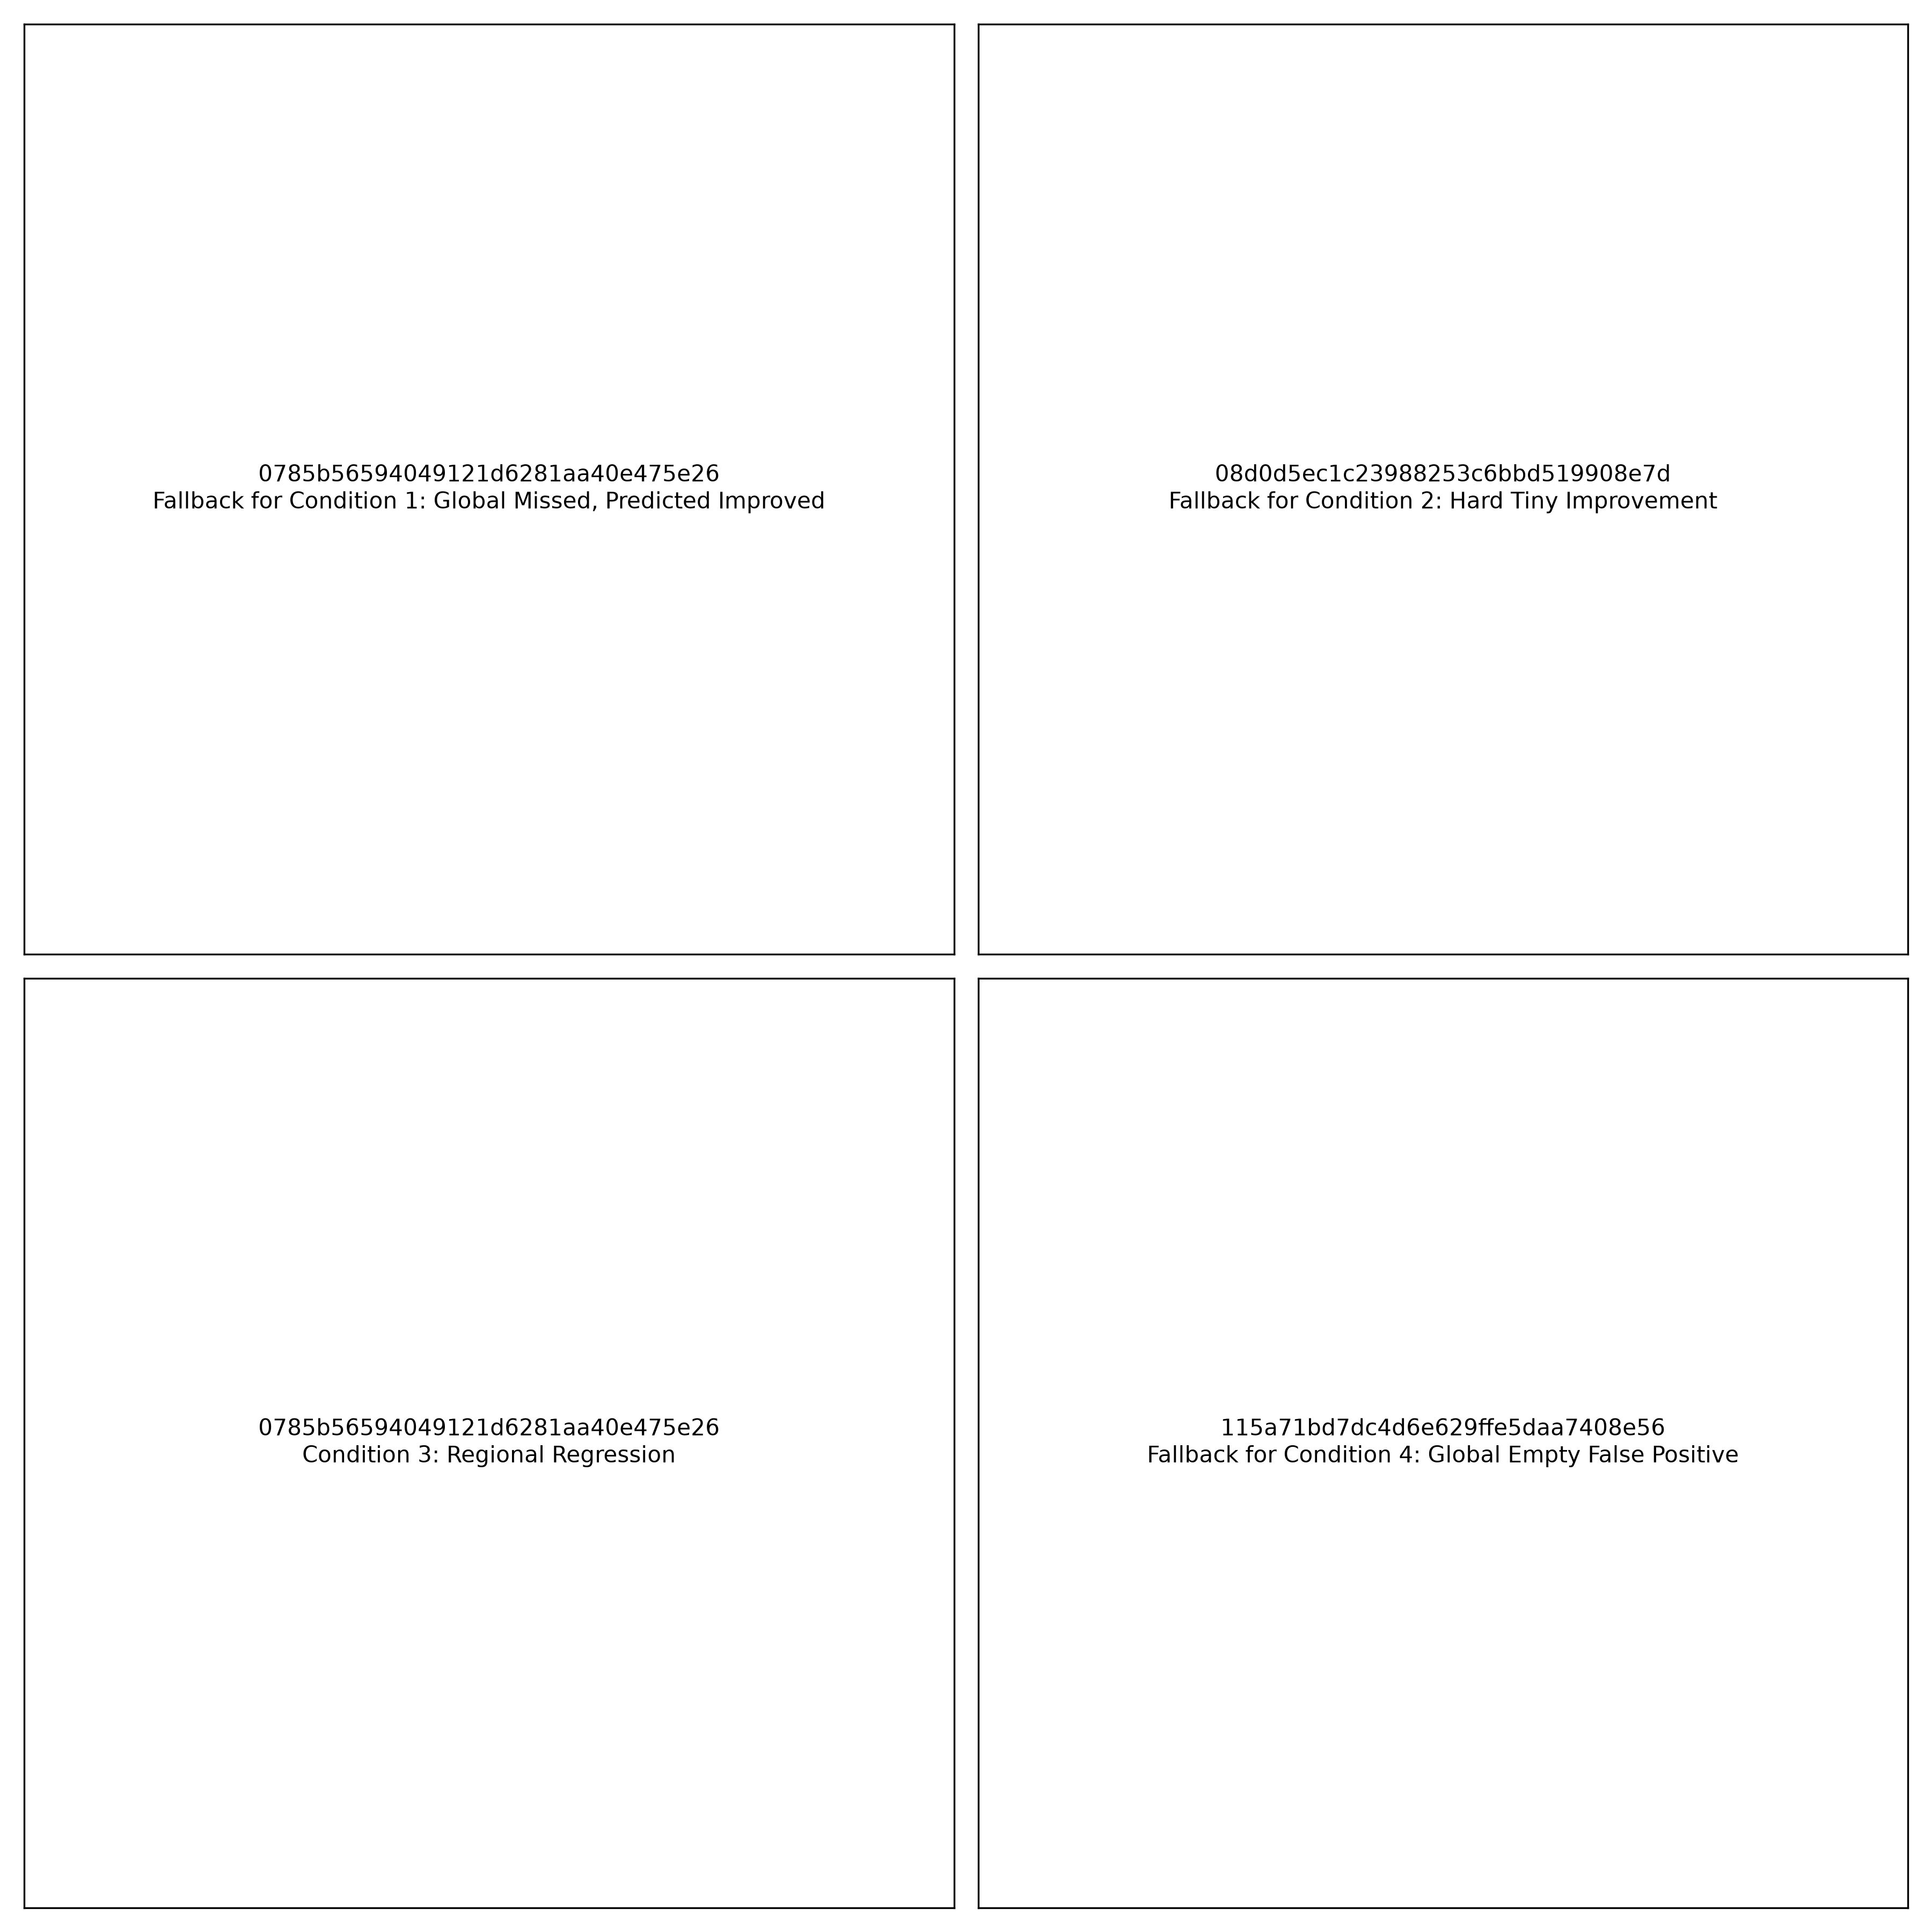

In [19]:
from IPython.display import Image, display
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
F = PROJECT_ROOT / 'reports/figures/phase14_part3c'
Q = PROJECT_ROOT / 'reports/qualitative/phase14_part3c'
display(Image(filename=str(F/'figure_A_overall_dice.png'), width=800))
display(Image(filename=str(F/'figure_B_recall_stratum.png'), width=800))
display(Image(filename=str(F/'figure_C_false_positives.png'), width=800))
display(Image(filename=str(F/'figure_D_empty_images.png'), width=800))
display(Image(filename=str(F/'figure_E_proposal_burden.png'), width=800))
display(Image(filename=str(F/'figure_F_runtime_stacked.png'), width=800))
display(Image(filename=str(F/'figure_G_gate_scatter.png'), width=800))
display(Image(filename=str(Q/'phase14_part3_qualitative_panel.png'), width=800))


## Part-3C/3D Final Canonical Corrected Audit
Loads the canonical corrected diagnostic audit and tables.

In [20]:
import json
import pandas as pd
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
with open(PROJECT_ROOT / 'reports/audits/phase14_part3_diagnostic_evaluation.json', 'r') as f:
    audit = json.load(f)
df_img = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase14_part3_image_metrics.csv')
val_sized = pd.read_csv(PROJECT_ROOT / 'reports/tables/kub_val_samples_sized.csv')
df_img = pd.merge(df_img, val_sized[['sample_id', 'view_type']], on='sample_id')
ff_samples = df_img[df_img['view_type'] == 'FULL_FIELD']
total_proposals = int(ff_samples['predicted_proposals'].sum())
mean_proposals = total_proposals / len(ff_samples)
print('=== GLOBAL 512 ===')
print(f'Tg: {audit["frozen_references"]["Tg"]:.6f}, Dg: {audit["frozen_references"]["Dg"]:.6f}')
print('=== ORACLE 512 ===')
print(f'To: {audit["official_512_space"]["To_512"]:.6f}, Do: {audit["official_512_space"]["Do_512"]:.6f}')
print('=== PREDICTED 512 ===')
print(f'Tp: {audit["official_512_space"]["Tp_512"]:.6f}, Dp: {audit["official_512_space"]["Dp_512"]:.6f}')
print('=== GATE ===')
print(f'G: {audit["official_512_space"]["G"]:.6f}')
print(f'R: {audit["official_512_space"]["R"]:.6f}')
print(f'Step 1: {audit["gates"]["step1_pass"]}')
print(f'Step 2: {audit["gates"].get("step2_status", audit["gates"].get("step2_pass"))}')
print(f'Step 3: {audit["gates"]["step3_pass"]}')
print(f'Final Classification: {audit["diagnostic_classification"]}')
print(f'Total Proposals: {total_proposals}')
print(f'Mean Proposals: {mean_proposals:.6f}')
print('Checkpoints: Global (4bffcf926227fb11029ead6bcd8e7dd8ed246e0f1678e3efb2ce4297439a3f2d), Stage-4D (ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d93b58c25bc967cbace), Regional (89ada72700385ed56b49b6caf34d9061349c24a566794176911b83fb0c8cd9f0)')


=== GLOBAL 512 ===
Tg: 0.780822, Dg: 0.652776
=== ORACLE 512 ===
To: 1.000000, Do: 0.815175
=== PREDICTED 512 ===
Tp: 0.890411, Dp: 0.383905
=== GATE ===
G: 0.219178
R: 0.500000
Step 1: True
Step 2: PASS
Step 3: False
Final Classification: DIAGNOSTIC_PRACTICAL_SIGNAL_INSUFFICIENT
Total Proposals: 494
Mean Proposals: 4.660377
Checkpoints: Global (4bffcf926227fb11029ead6bcd8e7dd8ed246e0f1678e3efb2ce4297439a3f2d), Stage-4D (ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d93b58c25bc967cbace), Regional (89ada72700385ed56b49b6caf34d9061349c24a566794176911b83fb0c8cd9f0)


## Read-Only Trained-Model KUB Stone Segmentation Demonstration
Deterministic inference on a representative KUB stone.

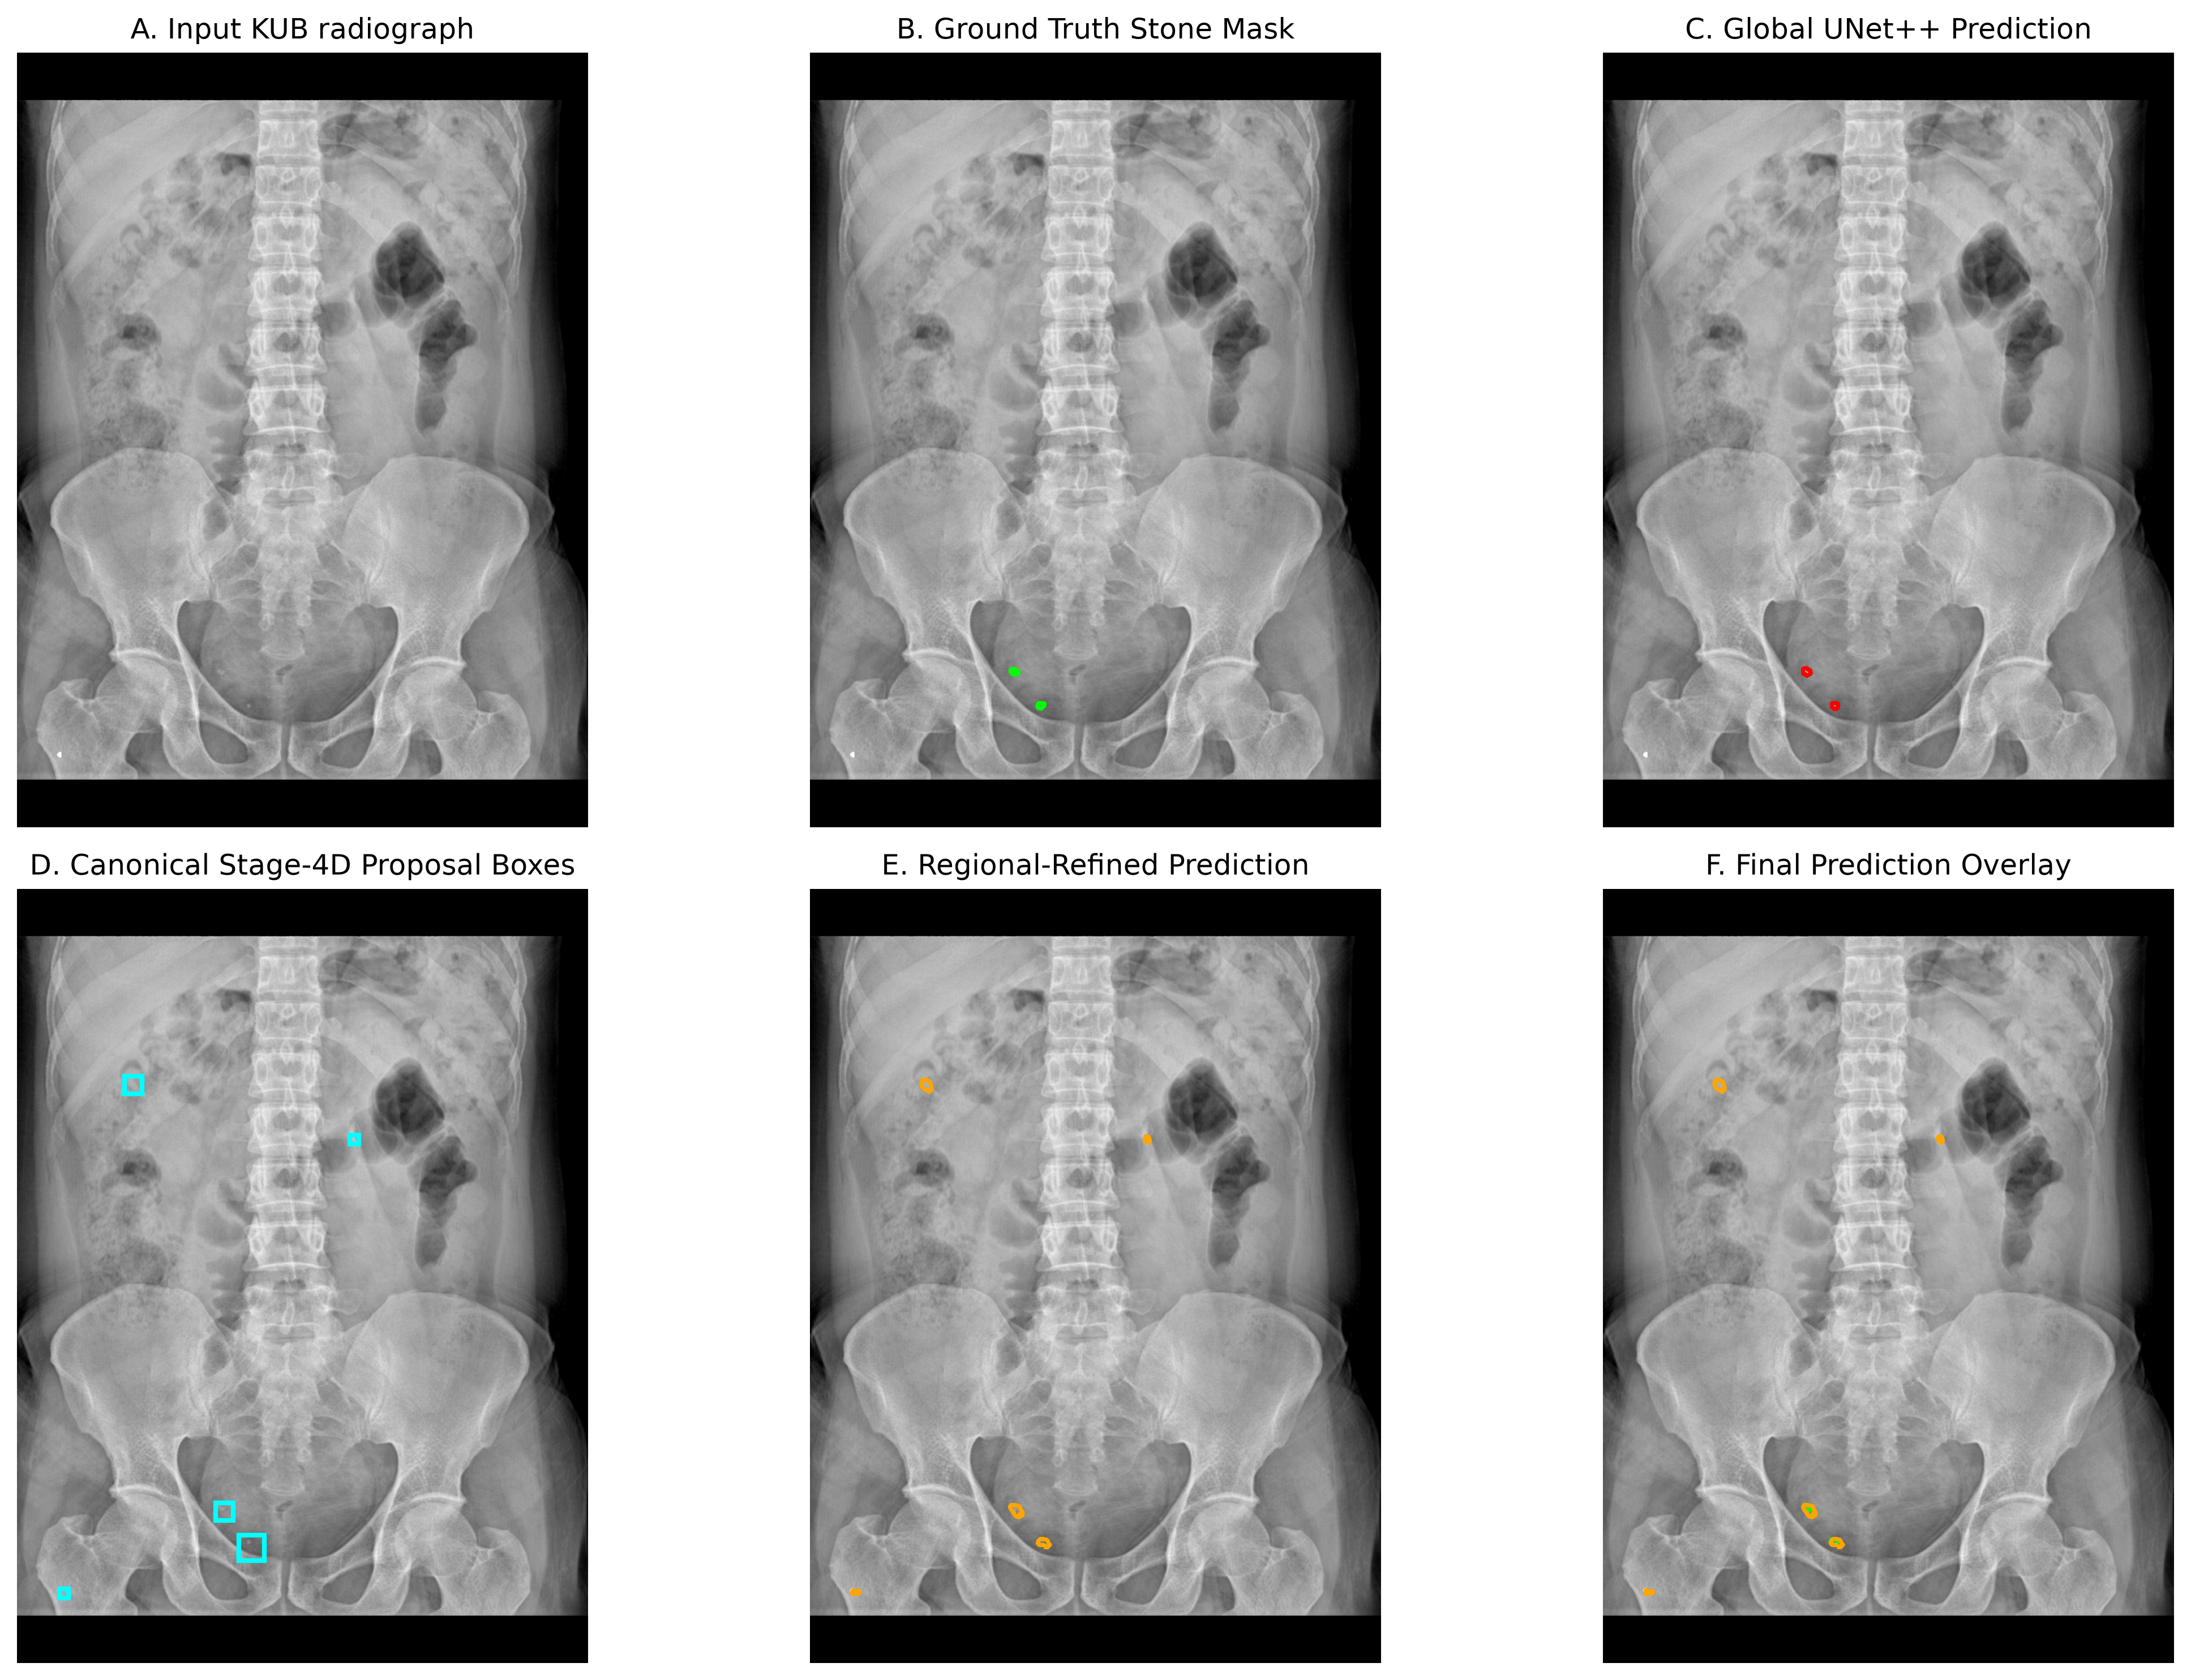

READ-ONLY DEMONSTRATION — NOT A SEPARATE EXPERIMENT
CUDA active: NVIDIA GeForce RTX 3060 Ti
Sample ID: 0785b56594049121d6281aa40e475e26, Split: VAL, FOV: FULL_FIELD, GT Components: 2
Proposal count: 5
ROI union fraction: 0.0032
Global Dice: 0.8036
Predicted-regional Dice: 0.3542
Global FP components: 0
Predicted FP components: 4


In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
import pandas as pd
from IPython.display import Image as IPImage, display
from src.models.factory import create_model
from src.utils.checkpointing import load_training_checkpoint
from src.data.transforms import SegmentationTransform
from src.data.regional_dataset import crop_and_preprocess
from src.inference.learned_roi import generate_localizer_rois
from src.inference.regional_evaluator import restore_regional_probability, aggregate_and_fuse
from src.inference.predicted_roi import union_roi_area_fraction
from src.metrics.object_metrics import object_metrics

# Governance & Environment Assertions
assert torch.cuda.is_available(), 'CUDA device required for read-only KUB demonstration (no silent CPU fallback allowed).'
device = torch.device('cuda')

def dice_binary(pred_mask: np.ndarray, gt_mask: np.ndarray, eps: float = 1e-7) -> float:
    p = pred_mask > 0
    g = gt_mask > 0
    tp = float((p & g).sum())
    fp = float((p & ~g).sum())
    fn = float((~p & g).sum())
    return (2.0 * tp + eps) / (2.0 * tp + fp + fn + eps)

def map_global_to_original(prob512: np.ndarray, meta, original_shape: tuple) -> np.ndarray:
    rw, rh = meta.resized_width, meta.resized_height
    left, top, right, bottom = meta.padding
    h_orig, w_orig = original_shape
    valid_512 = prob512[top:top+rh, left:left+rw]
    prob_pil = Image.fromarray((valid_512 * 255.0).astype(np.uint8)).resize(
        (w_orig, h_orig), Image.Resampling.BILINEAR
    )
    return np.asarray(prob_pil, dtype=np.float32) / 255.0

global_model = create_model('unetpp', in_channels=1, out_channels=1, base_channels=32).to(device)
load_training_checkpoint(PROJECT_ROOT/'checkpoints/phase10_kub_unetpp_seed42_512/best.pt', global_model, restore_rng=False, map_location=device)
global_model.eval()

localizer_model = create_model('kub_localizer', in_channels=1, out_channels=1, base_channels=16, heatmap_resolution=128).to(device)
load_training_checkpoint(PROJECT_ROOT/'checkpoints/phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1/best.pt', localizer_model, restore_rng=False, map_location=device)
localizer_model.eval()

regional_model = create_model('unet', in_channels=1, out_channels=1, base_channels=32).to(device)
load_training_checkpoint(PROJECT_ROOT/'checkpoints/phase14_diag_regional_unet_oracletrain_a3_seed42_v1/best.pt', regional_model, restore_rng=False, map_location=device)
regional_model.eval()

# Deterministic selection: lexicographically first FULL_FIELD VAL sample with >=1 GT stone component
val_sized = pd.read_csv(PROJECT_ROOT / 'reports/tables/kub_val_samples_sized.csv')
ff_samples = val_sized[(val_sized['view_type'] == 'FULL_FIELD') & (val_sized['component_count'] > 0)].sort_values('sample_id')
cand = ff_samples.iloc[0]
sid = cand['sample_id']
gt_comp_count = int(cand['component_count'])

raw_img = Image.open(cand['image_path']).convert('L')
raw_mask_pil = Image.open(cand['mask_path']).convert('L')
raw_mask = (np.asarray(raw_mask_pil) > 0).astype(np.uint8)

t_orig = SegmentationTransform(size=512, train=False)
tensor_g, _, meta_g = t_orig(raw_img, raw_mask_pil)

with torch.inference_mode():
    with torch.amp.autocast(device_type=device.type, enabled=True):
        logits_g = global_model(tensor_g.unsqueeze(0).to(device))
        prob512_g = torch.sigmoid(logits_g)[0, 0].float().cpu().numpy()
        logits_l = localizer_model(tensor_g.unsqueeze(0).to(device))
        prob128_l = torch.sigmoid(logits_l)[0, 0].float().cpu().numpy()
    proposals = generate_localizer_rois(prob128_l, meta_g, (raw_img.height, raw_img.width), 0.10, 0.20, 5, 0.30)
    r_probs, r_supp = [], []
    for p in proposals:
        geom = p['crop_geometry']
        c_pil, _ = crop_and_preprocess(raw_img, raw_mask_pil, geom, 256)
        c_t = torch.from_numpy(np.asarray(c_pil, dtype=np.float32)).unsqueeze(0) / 255.0
        with torch.amp.autocast(device_type=device.type, enabled=True):
            logits_r = regional_model(c_t.unsqueeze(0).to(device))
        p_r = torch.sigmoid(logits_r)[0, 0].float().cpu().numpy()
        rp, rs = restore_regional_probability(p_r, geom, (raw_img.height, raw_img.width))
        r_probs.append(rp)
        r_supp.append(rs)

    prob_orig_g = map_global_to_original(prob512_g, meta_g, (raw_img.height, raw_img.width))
    mask_orig_g = (prob_orig_g >= 0.50).astype(np.uint8)
    prob_prd = aggregate_and_fuse(prob_orig_g, r_probs, r_supp)
    mask_prd = (prob_prd >= 0.50).astype(np.uint8)

roi_union_frac, _ = union_roi_area_fraction(proposals, (raw_img.height, raw_img.width))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(raw_img, cmap='gray'); axes[0, 0].set_title('A. Input KUB radiograph')
axes[0, 1].imshow(raw_img, cmap='gray'); axes[0, 1].contour(raw_mask, colors='lime', linewidths=1.5); axes[0, 1].set_title('B. Ground Truth Stone Mask')
axes[0, 2].imshow(raw_img, cmap='gray'); axes[0, 2].contour(mask_orig_g, colors='red', linewidths=1.5); axes[0, 2].set_title('C. Global UNet++ Prediction')
axes[1, 0].imshow(raw_img, cmap='gray')
for p in proposals:
    g_box = p['crop_geometry']
    x1, y1, x2, y2 = g_box['x1'], g_box['y1'], g_box['x2'], g_box['y2']
    axes[1, 0].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='cyan', lw=2))
axes[1, 0].set_title('D. Canonical Stage-4D Proposal Boxes')
axes[1, 1].imshow(raw_img, cmap='gray'); axes[1, 1].contour(mask_prd, colors='orange', linewidths=1.5); axes[1, 1].set_title('E. Regional-Refined Prediction')
axes[1, 2].imshow(raw_img, cmap='gray'); axes[1, 2].contour(raw_mask, colors='lime', linewidths=1.5); axes[1, 2].contour(mask_prd, colors='orange', linewidths=1.5); axes[1, 2].set_title('F. Final Prediction Overlay')
for ax in axes.flat: ax.axis('off')
plt.tight_layout()

demo_out_path = PROJECT_ROOT / 'reports/figures/phase14_part3c/phase14_part3_demo_visualization.png'
fig.savefig(demo_out_path, dpi=300, bbox_inches='tight')
plt.close(fig)

# Explicitly embed display_data image/png in executed notebook output
display(IPImage(filename=str(demo_out_path), width=900))

g_dice = dice_binary(mask_orig_g, raw_mask)
p_dice = dice_binary(mask_prd, raw_mask)
g_fp = object_metrics(mask_orig_g, raw_mask, 1)["false_positive_predicted_components"]
p_fp = object_metrics(mask_prd, raw_mask, 1)["false_positive_predicted_components"]

print("READ-ONLY DEMONSTRATION — NOT A SEPARATE EXPERIMENT")
print(f"CUDA active: {torch.cuda.get_device_name(0)}")
print(f"Sample ID: {sid}, Split: VAL, FOV: FULL_FIELD, GT Components: {gt_comp_count}")
print(f"Proposal count: {len(proposals)}")
print(f"ROI union fraction: {roi_union_frac:.4f}")
print(f"Global Dice: {g_dice:.4f}")
print(f"Predicted-regional Dice: {p_dice:.4f}")
print(f"Global FP components: {g_fp}")
print(f"Predicted FP components: {p_fp}")
